# GRASP for the CVRPTW: Solomon, Homberger, 10,000 customers and real cities

**CesiCDP, ADEME call for expressions of interest, delivery route optimization.**
Owner of this notebook: **Farida** (GRASP, experimental study, deck). Team: Pablo (model,
exact method, Tabu Search), Dag (shared base, Simulated Annealing).

## 1. Introduction

**Contents.** Sections 2-9: Solomon benchmark on the team protocol. Section 10: Homberger
(400-1,000 customers). Section 11: 10,000 customers. Section 12: Paris vs São Paulo road
networks. Section 13: sensitivity to intrinsic and extrinsic variables. Section 14: conclusions.

### The problem
A depot sends identical trucks of capacity $Q$ to serve $n$ customers. Customer $i$ has a
demand $q_i$, a service duration $s_i$ and a time window $[e_i, l_i]$: service may not start
after $l_i$, and a truck that arrives before $e_i$ **waits on site**. Every customer is served
exactly once, every route starts and ends at the depot inside its window $[e_0, l_0]$, and at
most $K$ trucks are used. This is the CVRPTW (Level A of the brief); without windows it is the
CVRP (Level B). Both are NP-hard (the TSP is the special case $K = 1$, $Q = \infty$; see
notebook 01).

### Objective used in this notebook
Notebook 01 defines the team objective as the **total route duration with time-dependent
traffic**. For the Solomon benchmark we minimize the **total distance** instead (travel time =
distance, no traffic), because the best known solutions (BKS) of Solomon are distance values:
only with the same objective is the gap to the BKS valid. This is the same objective and the
same evaluation as Tabu Search and Simulated Annealing.

### Method
GRASP (Greedy Randomized Adaptive Search Procedure, Feo and Resende, 1995) is a multi-start
method: each iteration builds a solution with a randomized greedy heuristic, improves it with a
local search, and keeps the best feasible solution found. **GRASP-ILS** adds a short iterated
local search inside each iteration (Section 4.3). Both are the same code, `src/cvrp/grasp.py`.

### Team protocol (shared with Tabu Search and SA, `experiments/solomon_study.py`)
| Item | Value |
|---|---|
| Instances | all 56 Solomon instances (C1, C2, R1, R2, RC1, RC2), $n = 100$ |
| Distances | Euclidean, **truncated to one decimal** (the convention of the BKS) |
| Tuning set | C101, C201, R101, R201, RC101, RC201 (first instance of each class) |
| Test set | the other 50 instances, never used to choose a parameter |
| Seeds | 2 per tuning run, 10 per test run |
| Time limit | **20 s per run**, the same for every algorithm |
| Feasibility | every returned solution is checked by the shared `Solution.violations` |

## 2. Imports and configuration

`RECOMPUTE = True` runs every experiment from scratch, on `WORKERS` parallel processes (one
CPU core left free, never more processes than cores, so that every run really gets its 20 s).
Expected time: (144 tuning runs + 500 test runs) × 20 s / `WORKERS`, for example about
30 minutes with 7 workers. `RECOMPUTE = False` reloads the CSV files written by a previous
run in `results/`.

`QUICK_CHECK = True` only checks that the notebook runs end to end (1 s per run, fewer seeds):
its numbers are **not** valid results.

In [1]:
import sys
import time
from pathlib import Path

# Repository root = the folder that contains src/cvrp, wherever the kernel starts.
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "cvrp").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "experiments"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vrplib
from scipy import stats

import solomon_study as study            # team protocol: instances, split, seeds, time limit
from cvrp import Instance, Solution
from cvrp import grasp as G
from cvrp.grasp import GRASPParams, grasp
from cvrp.utils import gap_percent
from cvrp.viz import plot_routes

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
# Validated colorblind-safe palette: one color per family, type 2 drawn lighter.
FAMILY_COLOR = {"C": "#2a78d6", "R": "#eb6834", "RC": "#1baf7a"}
VARIANT_COLOR = {"GRASP": "#9a9a96", "GRASP-ILS": "#2a78d6"}
CLASSES = ["C1", "C2", "R1", "R2", "RC1", "RC2"]
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print("project folder:", ROOT.name)

ImportError: DLL load failed while importing dtypes: An Application Control policy has blocked this file.

In [ ]:
RECOMPUTE = True        # True: run everything (needed for the final version); False: reload CSVs
QUICK_CHECK = False     # True: 1 s per run and fewer seeds, only to test the notebook
WORKERS = study.WORKERS # parallel runs; lower it if the laptop must stay usable

TIME_LIMIT = 1.0 if QUICK_CHECK else study.TIME_LIMIT          # 20 s per run (team rule)
TUNING = study.TUNING                                            # 6 tuning instances
TUNE_SEEDS = study.TUNE_SEEDS[:1] if QUICK_CHECK else study.TUNE_SEEDS
TEST_SEEDS = study.TEST_SEEDS[:2] if QUICK_CHECK else study.TEST_SEEDS
GRID = study.ALGORITHMS["grasp"][1]                              # GRASP tuning grid
TAG = "_quick" if QUICK_CHECK else ""                            # quick runs never overwrite real ones
study.WORKERS = WORKERS
print(f"time limit {TIME_LIMIT:.0f} s, {WORKERS} workers, tuning seeds {TUNE_SEEDS}, "
      f"test seeds {TEST_SEEDS[0]}..{TEST_SEEDS[-1]}, grid {GRID}")

time limit 20 s, 7 workers, tuning seeds [101, 102], test seeds 1..10, grid {'alpha': [0.1, 0.3, 0.5], 'improvement': ['first', 'best'], 'perturb_kicks': [0, 90]}


## 3. Dataset loading

The 56 Solomon instances and their BKS files (`data/solomon/<name>.txt` and `.sol`) come from
the PyVRP/VRPLIB copy listed in `data/README.md`; they are git-ignored, so each person downloads
them once. `study.load` reads an instance with the team loader and truncates the distances to
one decimal.

**Convention check.** For every instance, the published BKS routes are evaluated with our
distance matrix and the shared evaluator: the cost must equal the published value and the
solution must be feasible. If this check passes, our gaps compare like with like.

In [ ]:
names = sorted(p.stem for p in study.DATA.glob("*.txt"))
missing = sorted(set(study.TUNING) - set(names))
assert len(names) == 56 and not missing, (
    f"{len(names)} Solomon files found in data/solomon (56 expected); see data/README.md")

rows = []
for name in names:
    inst = study.load(name)
    bks = Solution([list(r) for r in vrplib.read_solution(str(study.DATA / f"{name}.sol"))["routes"]])
    rows.append({"Dataset": name, "Class": name[:-2],  # C101 -> C1, RC205 -> RC2
                 "Set": "tuning" if name in TUNING else "test", "BKS": inst.best_known,
                 "BKS routes": len(bks), "Our cost of the BKS": round(bks.cost(inst), 2),
                 "BKS feasible": bks.is_feasible(inst),
                 "Window width (mean)": float(np.mean(inst.due_times[1:] - inst.ready_times[1:])),
                 "Horizon l0": inst.due_times[0]})
instances = pd.DataFrame(rows)
ok = (instances["BKS feasible"] & np.isclose(instances["Our cost of the BKS"], instances.BKS)).all()
print(f"{len(instances)} instances; BKS reproduced and feasible on all of them: {ok}")
(instances.groupby("Class")
          .agg(instances=("Dataset", "size"), tuning=("Set", lambda s: (s == "tuning").sum()),
               BKS_routes=("BKS routes", "mean"), window=("Window width (mean)", "mean"),
               horizon=("Horizon l0", "first"))
          .reindex(CLASSES).round(1))

56 instances; BKS reproduced and feasible on all of them: True


,instances,tuning,BKS_routes,window,horizon
Class,,,,,
C1,9,1,10.0,321.0,1236.0
C2,8,1,3.0,920.5,3390.0
R1,12,1,13.2,87.0,230.0
R2,11,1,5.5,453.7,1000.0
RC1,8,1,12.5,85.4,240.0
RC2,8,1,6.2,369.8,960.0


Type 1 classes (C1, R1, RC1) have a short horizon, so many trucks with short routes; type 2
classes (C2, R2, RC2) have a long horizon, so few trucks with long routes (about 30 customers
each), which makes each route harder to optimize.

## 4. GRASP implementation

The code is in `src/cvrp/grasp.py`. It reads the shared `Instance`, returns a shared `Solution`
and never modifies the teammates' modules. Pseudocode:

```
GRASP(instance, alpha, time limit):
    best = None
    while the time limit is not reached:
        S = RandomizedGreedyConstruction(alpha)        # 4.1
        if S uses more than K trucks: EliminateRoutes(S)
        S = LocalSearch(S)                             # 4.2 (VND)
        repeat perturb_kicks times (GRASP-ILS only):   # 4.3
            S' = LocalSearch(Kick(S));  if cost(S') < cost(S): S = S'
        if S is feasible (shared evaluator) and cost(S) < cost(best): best = S
    return best
```

### 4.1 Randomized adaptive construction
*Parallel insertion.* For every unrouted customer $u$ the code keeps its cheapest feasible
insertion in every open route, $c(u) = \min_{(a,b)} d_{au} + d_{ub} - d_{ab}$. After an
insertion only the modified route is re-evaluated: this is the **adaptive** part of GRASP.

*Score (regret).* The score of $u$ is $c_1(u) - (c_2(u) - c_1(u))$, with $c_1, c_2$ its best
and second best route: a customer with a large regret has only one good route left, so it is
served before that route fills up.

*Restricted candidate list.* $\text{RCL} = \{u : \text{score}(u) \le s_{\min} + \alpha\,(s_{\max} - s_{\min})\}$;
one customer is drawn at random from the RCL. $\alpha = 0$ is pure greedy, $\alpha = 1$ is random.

*New routes.* When no customer fits anywhere, a route is opened with a seed customer drawn among
the farthest from the depot or the earliest due ones.

### 4.2 Local search: granular Variable Neighborhood Descent

| Neighborhood | Move | Routes |
|---|---|---|
| Relocate | move one customer next to one of its neighbors | intra and inter |
| Swap | exchange two customers | inter |
| 2-opt* | exchange the tails of two routes | inter |
| Or-opt | move a chain of 2 or 3 consecutive customers | inter |
| Cross-exchange | exchange two segments of up to 2 customers | inter |
| 2-opt | reverse a segment | intra |

After any improvement the descent restarts from the first neighborhood; it stops when none
improves. `improvement="first"` applies the first improving move found, `"best"` the best one of
the whole neighborhood. Moves are only tried between a customer and its 20 nearest customers
(granular neighborhoods, Toth and Vigo 2003).

**O(1) time-window check.** Each route stores, at each position $k$, the service start $A_k$
and the latest feasible start $Z_k$ (Savelsbergh 1992):

$$A_k = \max\big(e_{p_k},\; A_{k-1} + s_{p_{k-1}} + d_{p_{k-1} p_k}\big), \qquad
Z_k = \min\big(l_{p_k},\; Z_{k+1} - s_{p_k} - d_{p_k p_{k+1}}\big).$$

Inserting $u$ between positions $k$ and $k+1$ is feasible if and only if
$t_u = \max(e_u, A_k + s_{p_k} + d_{p_k u}) \le l_u$ and $t_u + s_u + d_{u\,p_{k+1}} \le Z_{k+1}$.
The same test checks swap, Or-opt, cross-exchange and 2-opt* without re-simulating routes.
These caches only speed up the search: every kept solution is re-checked by the shared evaluator.

### 4.3 GRASP-ILS: intensification inside each iteration
With `perturb_kicks > 0`, after the descent the solution receives up to that many kicks: remove
a cluster of 10 to 20 % of the customers (a seed and its nearest neighbors), reinsert them at
their cheapest feasible place, descend again, and keep the result only if it is shorter. This is
an Iterated Local Search inside each GRASP iteration, a documented hybridization (Resende and
Ribeiro, 2010). `perturb_kicks = 0` is the plain GRASP. Section 6 compares both at the same
time budget.

### 4.4 Step by step on C101
One construction, then one local search:

construction : cost    987.8, 11 routes, feasible True, 16 ms
local search : cost    886.4, 11 routes, feasible True, 16 improving moves, 13 ms   (BKS 827.3)


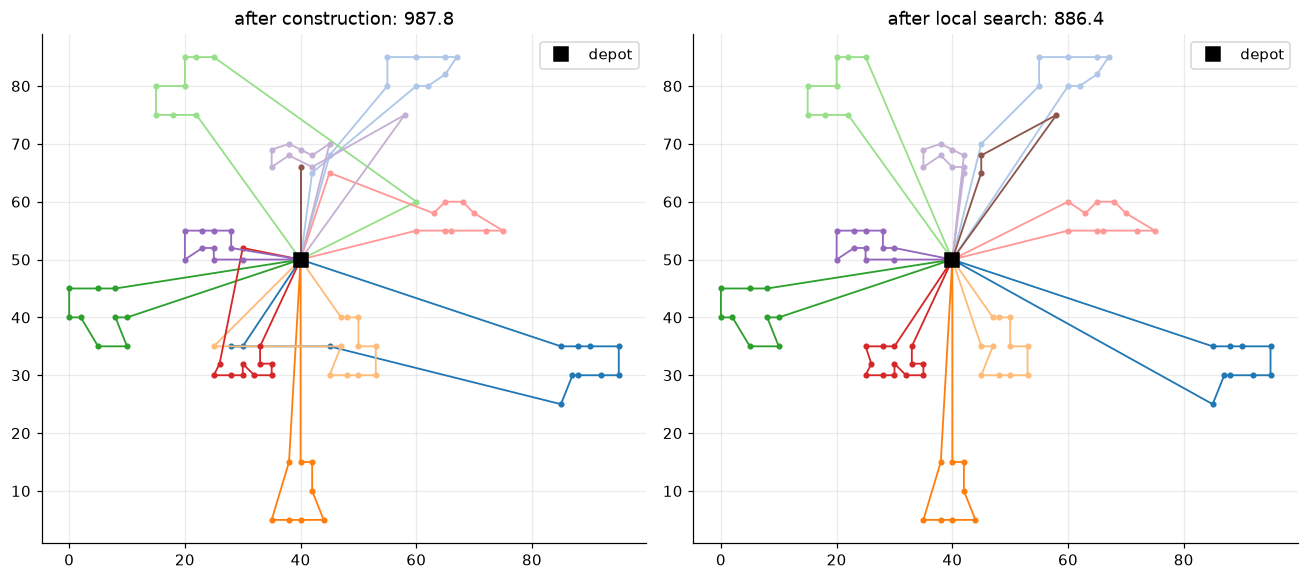

In [ ]:
import random

inst = study.load("C101")
params = GRASPParams(alpha=0.1)
model = G._Model(inst, params.n_neighbors)
rng = random.Random(42)

t = time.perf_counter()
state = G.construct(model, rng, params.alpha, params.construction, params.tw_weight)
built = state.to_solution()
print(f"construction : cost {built.cost(inst):8.1f}, {len(built)} routes, "
      f"feasible {built.is_feasible(inst)}, {(time.perf_counter() - t) * 1000:.0f} ms")
t = time.perf_counter()
moves = G._LocalSearch(model, state, rng, params).run()
improved = state.to_solution()
print(f"local search : cost {improved.cost(inst):8.1f}, {len(improved)} routes, "
      f"feasible {improved.is_feasible(inst)}, {moves} improving moves, "
      f"{(time.perf_counter() - t) * 1000:.0f} ms   (BKS {inst.best_known})")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
plot_routes(inst, built, ax=axes[0], title=f"after construction: {built.cost(inst):.1f}")
plot_routes(inst, improved, ax=axes[1], title=f"after local search: {improved.cost(inst):.1f}")
plt.tight_layout(); plt.show()

The local search removes the crossings and the long edges between clusters; both phases take
milliseconds on 100 customers, which leaves room for many iterations within 20 s.

## 5. Single-instance testing

Quick debugging entry point: one instance, one variant, one seed, the team time limit.

RC101, GRASP-ILS, seed 1, limit 20 s
  feasible: True   violations: none
  routes 17, distance 1641.4, BKS 1619.8, gap 1.33 %, 15 GRASP iterations in 20.0 s


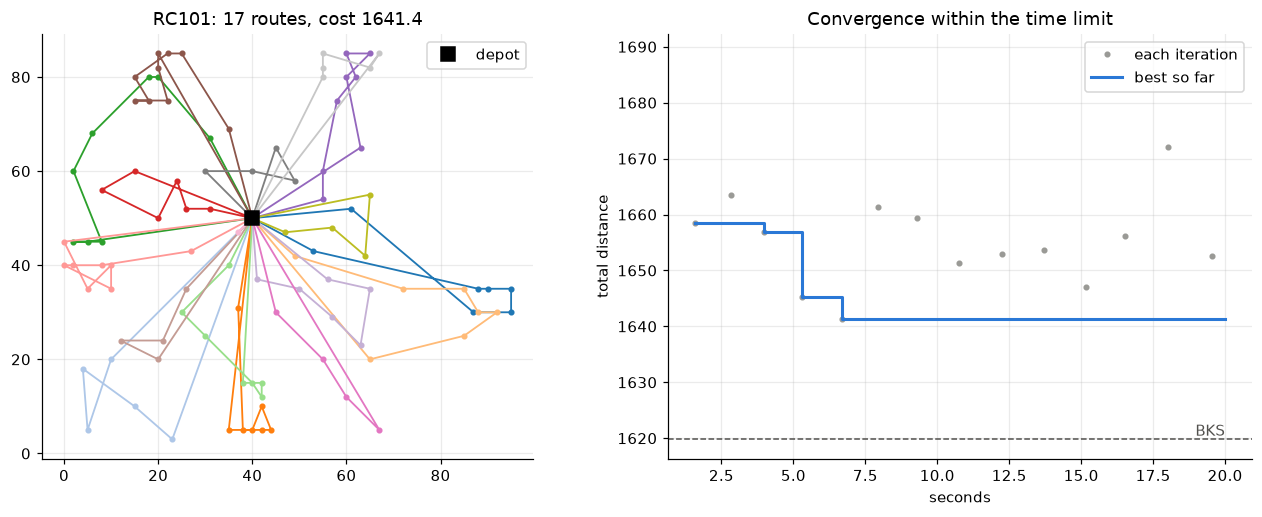

In [ ]:
INSTANCE = "RC101"
KICKS = 90            # 0 = plain GRASP, 90 = GRASP-ILS
SEED = 1

inst = study.load(INSTANCE)
res = grasp(inst, GRASPParams(alpha=0.1, perturb_kicks=KICKS, iterations=10**9,
                              time_limit=TIME_LIMIT), seed=SEED)
sol = res.best
print(f"{INSTANCE}, {'GRASP-ILS' if KICKS else 'GRASP'}, seed {SEED}, limit {TIME_LIMIT:.0f} s")
print(f"  feasible: {sol.is_feasible(inst)}   violations: {sol.violations(inst) or 'none'}")
print(f"  routes {len(sol)}, distance {res.cost:.1f}, BKS {inst.best_known}, "
      f"gap {gap_percent(res.cost, inst.best_known):.2f} %, "
      f"{res.iterations} GRASP iterations in {res.runtime:.1f} s")

h = pd.DataFrame(res.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
plot_routes(inst, sol, ax=axes[0])
axes[1].plot(h.seconds, h.after_ls, "o", ms=3, color="#9a9a96", label="each iteration")
axes[1].step(h.seconds, h.best, where="post", lw=2, color=VARIANT_COLOR["GRASP-ILS"], label="best so far")
axes[1].axhline(inst.best_known, ls="--", lw=1, color="#52514e")
axes[1].annotate("BKS", (h.seconds.max(), inst.best_known), ha="right", va="bottom", color="#52514e")
axes[1].set_xlabel("seconds"); axes[1].set_ylabel("total distance")
axes[1].set_title("Convergence within the time limit"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

## 6. Parameter tuning (tuning set only, 20 s per run)

Grid: $\alpha \in \{0.1, 0.3, 0.5\}$ × improvement $\in$ {first, best} × kicks $\in \{0, 90\}$,
on the 6 tuning instances with 2 seeds: 144 runs, all with the **same 20 s budget**, so every
comparison below is at equal time. The chosen parameters are those with the lowest mean gap
(`study.best_params`, the same rule as for Tabu Search).

In [ ]:
def with_limit(jobs):
    # Quick check only: shorten every run; real runs keep the team time limit.
    return [(n, a, dict(p, time_limit=TIME_LIMIT), s) for n, a, p, s in jobs] if QUICK_CHECK else jobs


tune_csv = RESULTS / f"solomon_tuning_grasp{TAG}.csv"
if RECOMPUTE:
    jobs = [(n, a, p, s) for n, a, p, s in study.tune_jobs(["grasp"]) if s in TUNE_SEEDS]
    tuning = study.run(with_limit(jobs), tune_csv)
else:
    tuning = pd.read_csv(tune_csv)
tuning["params"] = tuning["params"].str.replace(", 'time_limit': 1.0", "", regex=False)
p = tuning["params"].apply(eval)
tuning["alpha"] = p.str["alpha"]; tuning["improvement"] = p.str["improvement"]
tuning["kicks"] = p.str["perturb_kicks"]
tuning["variant"] = np.where(tuning.kicks > 0, "GRASP-ILS", "GRASP")
print(f"{len(tuning)} tuning runs, all feasible: {tuning.feasible.all()}, "
      f"runtime {tuning.seconds.min():.1f} to {tuning.seconds.max():.1f} s")
summary6 = (tuning.groupby(["variant", "alpha", "improvement"])
                  .agg(mean_gap=("gap", "mean"), worst_gap=("gap", "max"),
                       iterations=("iterations", "mean"))
                  .reset_index().sort_values("mean_gap"))
summary6

144 runs x 20 s on 7 workers, Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
25/144
50/144
75/144
100/144
125/144
144/144
144 tuning runs, all feasible: True, runtime 20.0 to 20.4 s


,variant,alpha,improvement,mean_gap,worst_gap,iterations
9,GRASP-ILS,0.3,first,1.65,5.12,8.33
7,GRASP-ILS,0.1,first,1.78,5.31,8.42
10,GRASP-ILS,0.5,best,1.92,6.55,7.17
11,GRASP-ILS,0.5,first,1.92,6.32,8.25
6,GRASP-ILS,0.1,best,1.98,6.75,7.17
8,GRASP-ILS,0.3,best,2.08,6.37,7.42
3,GRASP,0.3,first,2.71,10.11,145.75
5,GRASP,0.5,first,2.97,8.34,131.00
1,GRASP,0.1,first,3.16,9.73,154.92
4,GRASP,0.5,best,3.55,9.13,54.25


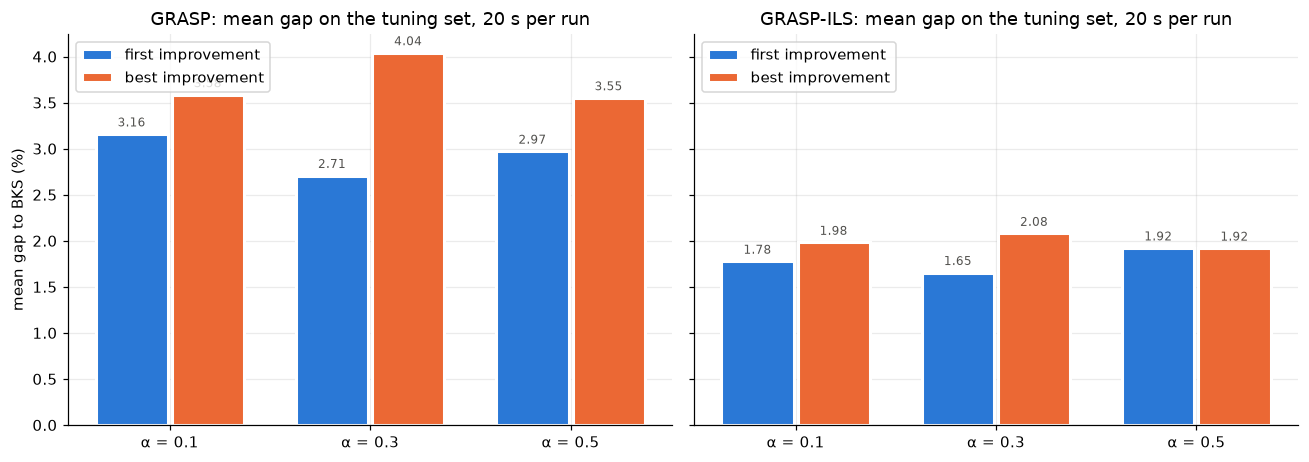

grasp tuning (mean gap %):
params
{'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 90}    1.65
{'alpha': 0.1, 'improvement': 'first', 'perturb_kicks': 90}    1.78
{'alpha': 0.5, 'improvement': 'best', 'perturb_kicks': 90}     1.92
{'alpha': 0.5, 'improvement': 'first', 'perturb_kicks': 90}    1.92
{'alpha': 0.1, 'improvement': 'best', 'perturb_kicks': 90}     1.98
{'alpha': 0.3, 'improvement': 'best', 'perturb_kicks': 90}     2.08
{'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 0}     2.71
{'alpha': 0.5, 'improvement': 'first', 'perturb_kicks': 0}     2.97
{'alpha': 0.1, 'improvement': 'first', 'perturb_kicks': 0}     3.16
{'alpha': 0.5, 'improvement': 'best', 'perturb_kicks': 0}      3.55
{'alpha': 0.1, 'improvement': 'best', 'perturb_kicks': 0}      3.58
{'alpha': 0.3, 'improvement': 'best', 'perturb_kicks': 0}      4.04

Chosen parameters for the test campaign: {'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 90}
Best plain GRASP setting: alpha 0.3, first impro

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, variant in zip(axes, ["GRASP", "GRASP-ILS"]):
    s = summary6[summary6.variant == variant]
    for k, (im, color) in enumerate((("first", "#2a78d6"), ("best", "#eb6834"))):
        v = s[s.improvement == im].set_index("alpha").reindex([0.1, 0.3, 0.5])
        xs = np.arange(3) + (k - 0.5) * 0.38
        ax.bar(xs, v.mean_gap, 0.36, color=color, label=f"{im} improvement", edgecolor="white", linewidth=2)
        for xi, g in zip(xs, v.mean_gap):
            ax.text(xi, g + 0.05, f"{g:.2f}", ha="center", va="bottom", fontsize=8, color="#52514e")
    ax.set_xticks(range(3), ["α = 0.1", "α = 0.3", "α = 0.5"])
    ax.set_title(f"{variant}: mean gap on the tuning set, {TIME_LIMIT:.0f} s per run")
    ax.legend(loc="upper left")
axes[0].set_ylabel("mean gap to BKS (%)")
plt.tight_layout(); plt.show()

CHOSEN = study.best_params(tuning, "grasp")
best_plain = summary6[summary6.variant == "GRASP"].iloc[0]
best_ils = summary6[summary6.variant == "GRASP-ILS"].iloc[0]
print(f"\nChosen parameters for the test campaign: {CHOSEN}")
print(f"Best plain GRASP setting: alpha {best_plain.alpha}, {best_plain.improvement} improvement, "
      f"mean gap {best_plain.mean_gap:.2f} %")
print(f"Best GRASP-ILS setting  : alpha {best_ils.alpha}, {best_ils.improvement} improvement, "
      f"mean gap {best_ils.mean_gap:.2f} %")

Read the two panels side by side: the right one (GRASP-ILS) against the left one (plain GRASP)
answers "more starts or deeper starts at the same 20 s?", and within each panel the bars show
the effect of $\alpha$ and of first vs best improvement. The printed lines give the numbers.

### 6.1 Plain GRASP vs GRASP-ILS per tuning instance (equal time)

In [ ]:
a, im = CHOSEN["alpha"], CHOSEN["improvement"]
pair = (tuning[(tuning.alpha == a) & (tuning.improvement == im)]
        .pivot_table(index="instance", columns="variant", values="gap", aggfunc="mean")
        .reindex(TUNING))
pair["difference (pts)"] = pair["GRASP"] - pair["GRASP-ILS"]
display(pair.round(2))
better = int((pair["difference (pts)"] > 1e-9).sum())
print(f"alpha {a}, {im} improvement: GRASP-ILS is better on {better} of {len(pair)} tuning "
      f"instances; mean gap {pair['GRASP'].mean():.2f} % (GRASP) vs {pair['GRASP-ILS'].mean():.2f} % (GRASP-ILS).")

variant,GRASP,GRASP-ILS,difference (pts)
instance,,,
C101,0.00,0.00,0.00
C201,0.00,0.00,0.00
R101,0.58,0.00,0.58
R201,5.76,4.21,1.55
RC101,2.91,1.92,0.98
RC201,7.00,3.79,3.21


alpha 0.3, first improvement: GRASP-ILS is better on 4 of 6 tuning instances; mean gap 2.71 % (GRASP) vs 1.65 % (GRASP-ILS).


## 7. Test campaign: 50 instances × 10 seeds × 20 s

The chosen parameters run on the 50 test instances with seeds 1 to 10, through the same
`study.run` as Tabu Search. The CSV `results/solomon_benchmark_grasp.csv` has the same columns
as the Tabu Search one, so notebook 03 can put them side by side.

In [ ]:
bench_csv = RESULTS / f"solomon_benchmark_grasp{TAG}.csv"
if RECOMPUTE:
    jobs = [j for j in study.test_jobs({"grasp": CHOSEN}) if j[3] in TEST_SEEDS]
    t0 = time.perf_counter()
    bench = study.run(with_limit(jobs), bench_csv)
    print(f"campaign wall time: {(time.perf_counter() - t0) / 60:.1f} min")
else:
    bench = pd.read_csv(bench_csv)
bench["class"] = bench.instance.str[:-2]  # C101 -> C1, RC205 -> RC2
bench["family3"] = bench["class"].str[:-1]
bench["bks_routes"] = bench.instance.map(instances.set_index("Dataset")["BKS routes"])
print(f"{len(bench)} runs on {bench.instance.nunique()} instances, seeds {sorted(bench.seed.unique().tolist())}")
print(f"feasible: {bench.feasible.mean():.0%}   runtime per run: mean {bench.seconds.mean():.1f} s, "
      f"max {bench.seconds.max():.1f} s (limit {TIME_LIMIT:.0f} s)")

500 runs x 20 s on 7 workers, Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
25/500
50/500
75/500
100/500
125/500
150/500
175/500
200/500
225/500
250/500
275/500
300/500
325/500
350/500
375/500
400/500
425/500
450/500
475/500
500/500
campaign wall time: 24.1 min
500 runs on 50 instances, seeds [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
feasible: 100%   runtime per run: mean 20.0 s, max 20.2 s (limit 20 s)


### 7.1 Results per instance (over the seeds)

In [ ]:
per_inst = (bench.groupby(["class", "instance"])
                 .agg(BKS=("best_known", "first"), best=("cost", "min"), mean=("cost", "mean"),
                      gap_best=("gap", "min"), gap_mean=("gap", "mean"), gap_std=("gap", "std"),
                      routes=("routes", "mean"), bks_routes=("bks_routes", "first"),
                      seconds=("seconds", "mean"))
                 .reset_index())
per_inst.round(2)

,class,instance,BKS,best,mean,gap_best,gap_mean,gap_std,routes,bks_routes,seconds
0,C1,C102,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.02
1,C1,C103,826.3,826.3,826.30,0.00,0.00,0.00,10.0,10,20.02
2,C1,C104,822.9,822.9,826.28,0.00,0.41,0.72,10.0,10,20.04
3,C1,C105,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.03
4,C1,C106,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.01
5,C1,C107,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.01
6,C1,C108,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.02
7,C1,C109,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.03
8,C2,C202,589.1,589.1,589.10,0.00,0.00,0.00,3.0,3,20.02
9,C2,C203,588.7,588.7,588.70,0.00,0.00,0.00,3.0,3,20.04


## 8. Results and visualization

### 8.1 Gap per class

,instances,mean_gap,median_gap,worst_gap,runs_le_7,routes,bks_routes,seconds
class,,,,,,,,
C1,8,0.05,0.00,2.41,100.00,10.00,10.00,20.02
C2,7,0.08,0.00,0.60,100.00,3.00,3.00,20.02
R1,11,1.04,0.91,3.60,100.00,12.69,12.64,20.03
R2,10,3.11,3.02,8.06,98.00,3.77,5.20,20.03
RC1,7,2.08,1.92,4.82,100.00,12.77,12.14,20.03
RC2,7,3.31,2.97,9.51,94.29,4.61,5.86,20.02


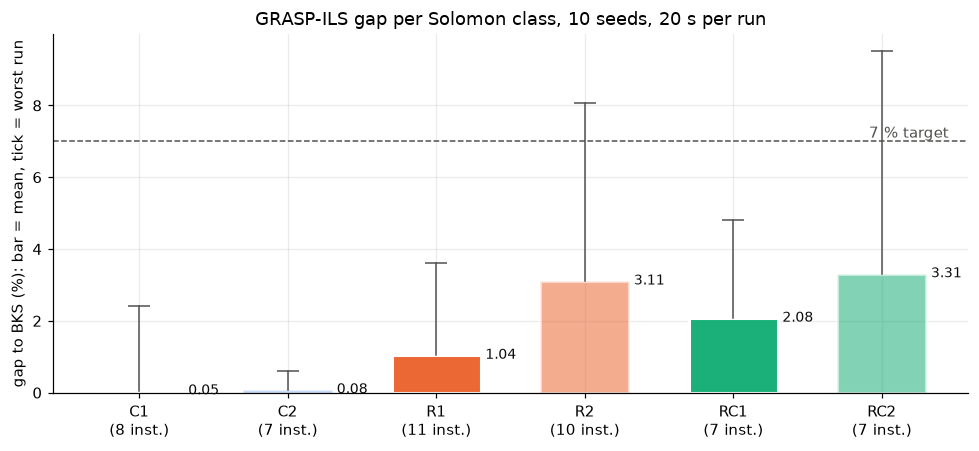

In [ ]:
cls = (bench.groupby("class")
            .agg(instances=("instance", "nunique"), mean_gap=("gap", "mean"),
                 median_gap=("gap", "median"), worst_gap=("gap", "max"),
                 runs_le_7=("gap", lambda g: 100 * (g <= 7).mean()),
                 routes=("routes", "mean"), bks_routes=("bks_routes", "mean"),
                 seconds=("seconds", "mean"))
            .reindex(CLASSES))
display(cls.round(2))

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, c in enumerate(CLASSES):
    color, light = FAMILY_COLOR[c[:-1]], c.endswith("2")
    ax.bar(i, cls.loc[c, "mean_gap"], 0.6, color=color, alpha=0.55 if light else 1.0,
           edgecolor="white", linewidth=2)
    ax.plot([i, i], [cls.loc[c, "mean_gap"], cls.loc[c, "worst_gap"]], color="#52514e", lw=1)
    ax.plot(i, cls.loc[c, "worst_gap"], "_", ms=14, color="#52514e")
    ax.text(i + 0.33, cls.loc[c, "mean_gap"], f"{cls.loc[c, 'mean_gap']:.2f}", va="center",
            fontsize=9, color="#0b0b0b")
ax.axhline(7, ls="--", lw=1, color="#52514e")
ax.annotate("7 % target", (5.45, 7), ha="right", va="bottom", color="#52514e")
ax.set_xticks(range(6), [f"{c}\n({int(cls.loc[c, 'instances'])} inst.)" for c in CLASSES])
ax.set_ylabel("gap to BKS (%): bar = mean, tick = worst run")
ax.set_title(f"GRASP-ILS gap per Solomon class, {len(TEST_SEEDS)} seeds, {TIME_LIMIT:.0f} s per run")
plt.tight_layout(); plt.show()

In [ ]:
worst_class = cls.mean_gap.idxmax()
print(f"Lowest mean gap: {cls.mean_gap.idxmin()} ({cls.mean_gap.min():.2f} %). "
      f"Highest: {worst_class} ({cls.mean_gap.max():.2f} %). "
      f"Type 1 mean {bench[bench['class'].str.endswith('1')].gap.mean():.2f} %, "
      f"type 2 mean {bench[bench['class'].str.endswith('2')].gap.mean():.2f} %.")
print(f"Runs at or below 7 %: {100 * (bench.gap <= 7).mean():.1f} % of {len(bench)}; "
      f"worst run {bench.gap.max():.2f} % ({bench.loc[bench.gap.idxmax(), 'instance']}).")

Lowest mean gap: C1 (0.05 %). Highest: RC2 (3.31 %). Type 1 mean 1.02 %, type 2 mean 2.29 %.
Runs at or below 7 %: 98.8 % of 500; worst run 9.51 % (RC208).


### 8.2 Gap per instance

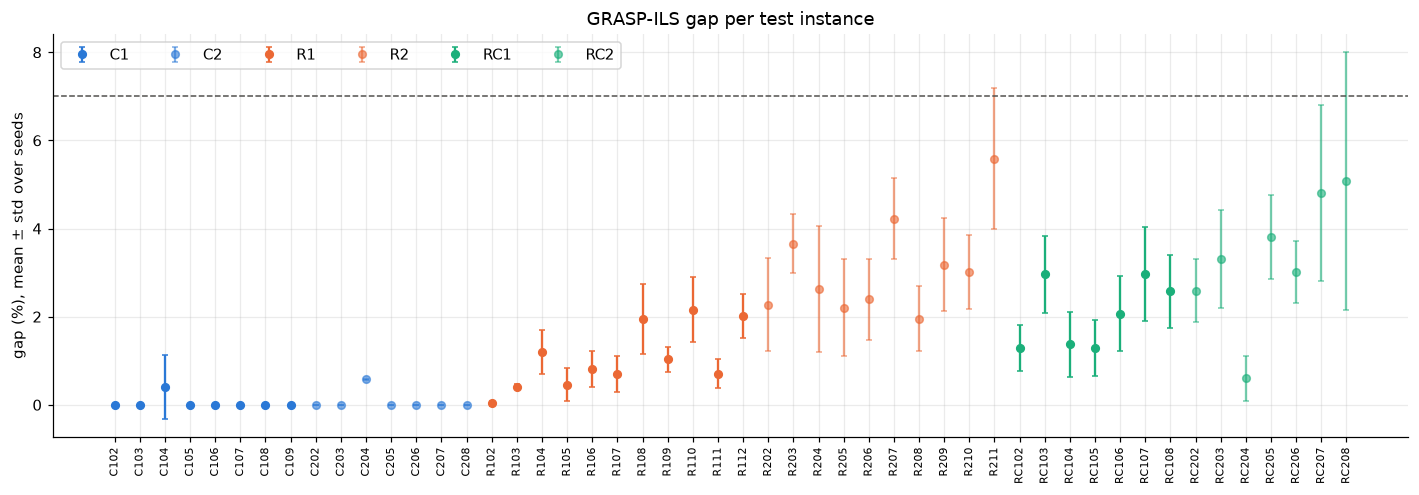

five hardest instances (mean gap %): R211 5.58, RC208 5.07, RC207 4.80, R207 4.22, RC205 3.81


In [ ]:
order = per_inst.sort_values(["class", "instance"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 4.6))
for c in CLASSES:
    s = order[order["class"] == c]
    color = FAMILY_COLOR[c[:-1]]
    ax.errorbar(s.index, s.gap_mean, yerr=s.gap_std, fmt="o", ms=5, capsize=2, color=color,
                alpha=0.6 if c.endswith("2") else 1.0, label=c)
ax.axhline(7, ls="--", lw=1, color="#52514e")
ax.set_xticks(order.index, order.instance, rotation=90, fontsize=7)
ax.set_ylabel("gap (%), mean ± std over seeds")
ax.set_title("GRASP-ILS gap per test instance")
ax.legend(ncol=6, loc="upper left")
plt.tight_layout(); plt.show()
hard = per_inst.nlargest(5, "gap_mean")[["instance", "gap_mean", "gap_std"]]
print("five hardest instances (mean gap %):", ", ".join(f"{r.instance} {r.gap_mean:.2f}" for r in hard.itertuples()))

### 8.3 Runtime and number of iterations

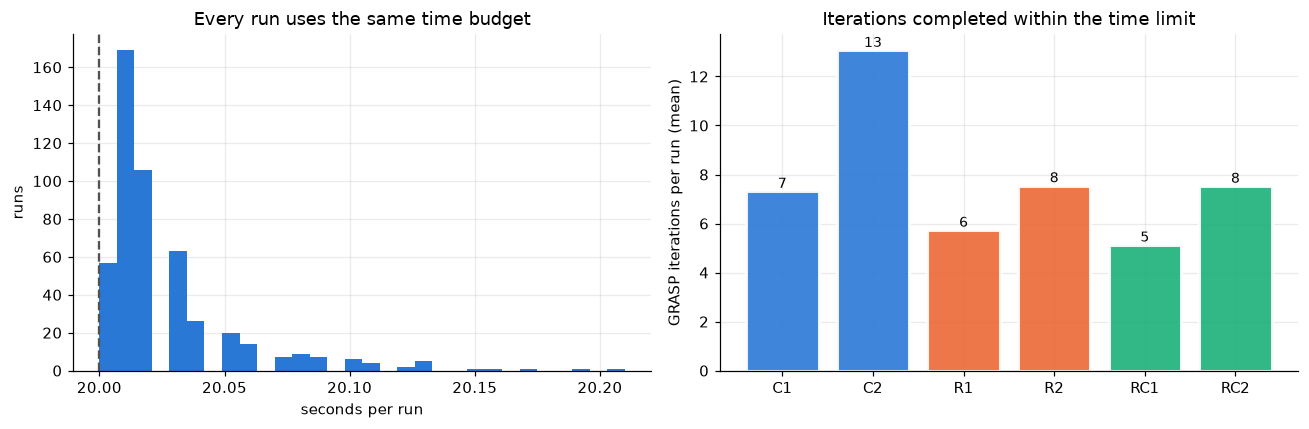

runtime: 20.00 to 20.21 s; iterations per run: C1 7, C2 13, R1 6, R2 8, RC1 5, RC2 8


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(bench.seconds, bins=30, color="#2a78d6")
axes[0].axvline(TIME_LIMIT, ls="--", color="#52514e")
axes[0].set_xlabel("seconds per run"); axes[0].set_ylabel("runs")
axes[0].set_title("Every run uses the same time budget")
it = bench.groupby("class").iterations.mean().reindex(CLASSES)
axes[1].bar(range(6), it, color=[FAMILY_COLOR[c[:-1]] for c in CLASSES],
            alpha=0.9, edgecolor="white", linewidth=2)
for i, v in enumerate(it):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9)
axes[1].set_xticks(range(6), CLASSES); axes[1].set_ylabel("GRASP iterations per run (mean)")
axes[1].set_title("Iterations completed within the time limit")
plt.tight_layout(); plt.show()
print(f"runtime: {bench.seconds.min():.2f} to {bench.seconds.max():.2f} s; iterations per run: "
      + ", ".join(f"{c} {v:.0f}" for c, v in it.items()))

The runtime is fixed by the protocol; what changes between classes is how many GRASP iterations
fit in it: long type 2 routes make each local search slower, so fewer starts are explored.

### 8.4 Stability across seeds

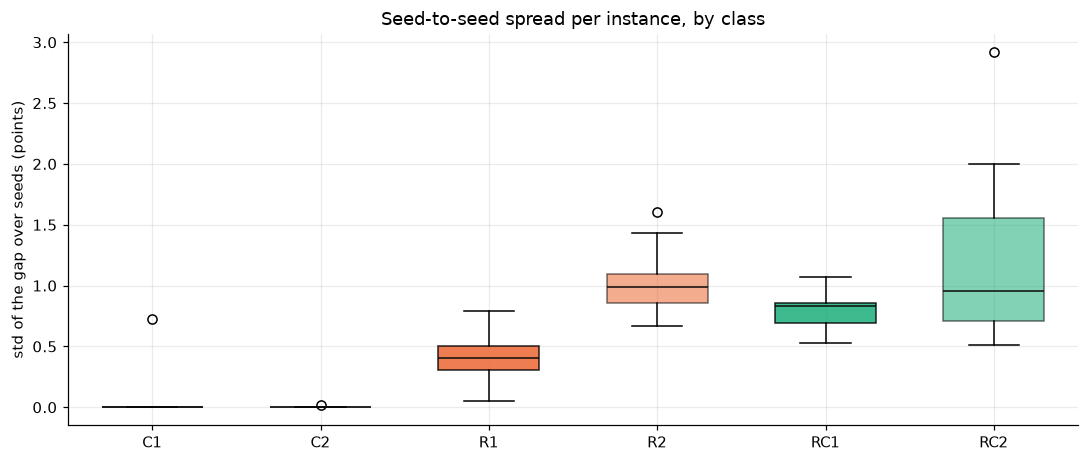

median seed-to-seed std: 0.58 points; largest: 2.92 (RC208)


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.3))
data = [bench[bench["class"] == c].groupby("instance").gap.std().values for c in CLASSES]
bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={"color": "#0b0b0b"})
for patch, c in zip(bp["boxes"], CLASSES):
    patch.set_facecolor(FAMILY_COLOR[c[:-1]]); patch.set_alpha(0.55 if c.endswith("2") else 0.85)
ax.set_xticks(range(1, 7), CLASSES)
ax.set_ylabel("std of the gap over seeds (points)")
ax.set_title("Seed-to-seed spread per instance, by class")
plt.tight_layout(); plt.show()
spread = bench.groupby("instance").gap.std()
print(f"median seed-to-seed std: {spread.median():.2f} points; largest: {spread.max():.2f} ({spread.idxmax()})")

### 8.5 Computation time against instance size

,n,routes,feasible,seconds per iteration
0,100,6,True,0.04
1,200,12,True,0.11
2,400,23,True,0.42
3,1000,54,True,3.42
4,2000,111,True,17.97


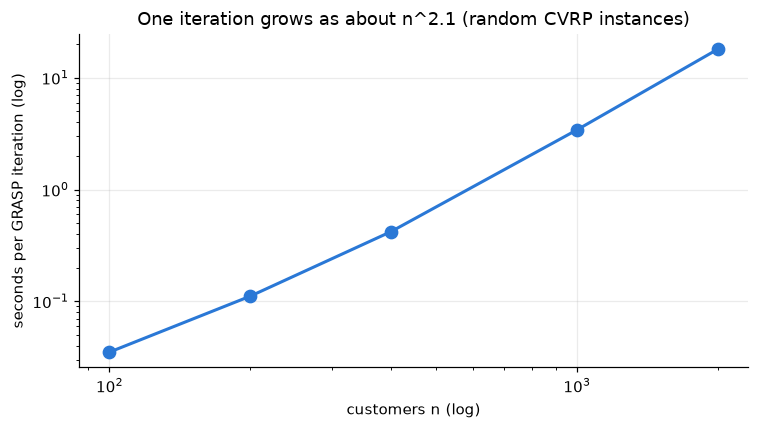

In [ ]:
scale_rows = []
for n in (100, 200, 400, 1000, 2000):
    inst = Instance.random(n, capacity=100, seed=1)
    r = grasp(inst, GRASPParams(iterations=2), seed=1)
    scale_rows.append({"n": n, "routes": len(r.best), "feasible": r.best.is_feasible(inst),
                       "seconds per iteration": r.runtime / r.iterations})
scale = pd.DataFrame(scale_rows)
slope = np.polyfit(np.log(scale.n), np.log(scale["seconds per iteration"]), 1)[0]
display(scale.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(scale.n, scale["seconds per iteration"], "o-", lw=2, ms=8, color="#2a78d6")
ax.set_xlabel("customers n (log)"); ax.set_ylabel("seconds per GRASP iteration (log)")
ax.set_title(f"One iteration grows as about n^{slope:.1f} (random CVRP instances)")
plt.tight_layout(); plt.show()

Random CVRP instances of growing size (no time windows), one construction and local search
each: the fitted exponent is the empirical complexity of one iteration, which shows that
instances of several thousand customers stay solvable, as the brief requires.

## 9. Statistical performance analysis

Unit of analysis: the instance (team design). For each class: the mean gap with a 95 %
confidence interval over the per-instance means (Student $t$), the share of runs at or under
7 %, and the spread over seeds. The comparison with Tabu Search and SA (Friedman test with Holm
correction) is done in notebook 03 on the shared CSV files.

In [ ]:
def ci95(v):
    v = np.asarray(v, dtype=float)
    return stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else np.nan

inst_means = bench.groupby(["class", "instance"]).gap.mean().reset_index()
table9 = (inst_means.groupby("class").gap
          .agg(instances="size", mean="mean", ci95=ci95, min="min", max="max").reindex(CLASSES))
table9.loc["all 50"] = [inst_means.gap.size, inst_means.gap.mean(), ci95(inst_means.gap),
                        inst_means.gap.min(), inst_means.gap.max()]
display(table9.round(2))

w = stats.wilcoxon(pair["GRASP"], pair["GRASP-ILS"], alternative="greater", zero_method="zsplit")
print(f"Plain GRASP vs GRASP-ILS on the {len(pair)} tuning instances (alpha {a}, {im}, equal time): "
      f"Wilcoxon W = {w.statistic:.1f}, p = {w.pvalue:.3f}. With 6 instances the smallest "
      f"possible p is 1/64 = 0.016, so this test is indicative only.")

,instances,mean,ci95,min,max
class,,,,,
C1,8,0.05,0.12,0.00,0.41
C2,7,0.08,0.20,0.00,0.58
R1,11,1.04,0.48,0.03,2.16
R2,10,3.11,0.80,1.95,5.58
RC1,7,2.08,0.71,1.29,2.97
RC2,7,3.31,1.39,0.60,5.07
all 50,50,1.63,0.44,0.00,5.58


Plain GRASP vs GRASP-ILS on the 6 tuning instances (alpha 0.3, first, equal time): Wilcoxon W = 19.5, p = 0.062. With 6 instances the smallest possible p is 1/64 = 0.016, so this test is indicative only.


## 10. Scaling up: Homberger instances (400, 800 and 1,000 customers)

Solomon instances all have 100 customers. To test GRASP on larger CVRPTW instances we use Dag's
Homberger study (`experiments/homberger_study.py`, data in `data/homberger/`): one R1 instance per
size, **seeds 1 to 10, 20 s per run**, distances truncated to one decimal, depot service 0, gap to
the PyVRP reference solution (best known, not a proven optimum). Same instances, same loader,
same budget and same evaluator as Dag's SA, so the numbers are directly comparable.
**Target: gap within 7-10 %.**

### Why the Solomon setting does not scale
With the Solomon setting (full VND passes, kicks of 10-20 % of the customers), one GRASP-ILS
iteration on `R1_10_1` takes about 16 s: construction 2.5 s, first descent 2.9 s, and then each
kick removes 100-200 customers and **re-scans all 1,000 customers** (about 1 s per kick). Only one
or two iterations fit in 20 s, and the gap stays above 11 %.

Two changes in `src/cvrp/grasp.py`, both **opt-in**, so the default (Solomon) behavior and the
results of sections 6-9 are unchanged:

| Parameter | Solomon setting | Large-instance setting | Effect |
|---|---|---|---|
| `local_search` | `"vnd"` | `"dlb"` | localized descent with *don't-look bits* (Bentley, 1992): after a move or a kick only the customers of the changed routes are re-examined; the time limit is also checked inside the descent |
| `kick_max` | none (10-20 % of $n$) | 30 customers | a kick stays local, so it costs milliseconds instead of a second |
| `perturb_kicks` | 90 | 300 per start | many cheap kicks per GRASP start |

`GRASP` below is the plain multi-start (construction + descent, no kicks) with the new descent;
`GRASP-ILS` adds the kicks. The large setting was fixed after a few probe runs on
`R1_10_1` (seed 1), not tuned on the 10-seed results; with only three Homberger instances there
is no separate tuning set, which is a limitation to keep in mind.

In [3]:
import os
import grasp_large_study as L          # experiments/grasp_large_study.py (jobs of sections 10-13)
import homberger_study as homberger     # Dag's loader and reference check

RECOMPUTE_LARGE = RECOMPUTE             # False: reload results/grasp_*.csv
L.WORKERS = WORKERS
LARGE_TAG = "_quick" if QUICK_CHECK else ""
LARGE_LIMIT = 2.0 if QUICK_CHECK else 20.0
LARGE_SEEDS = range(1, 3) if QUICK_CHECK else range(1, 11)


def run_or_load(name, jobs):
    # Run the jobs (parallel workers) and save the CSV, or reload a previous run.
    path = RESULTS / f"grasp_{name}{LARGE_TAG}.csv"
    if RECOMPUTE_LARGE or not path.exists():
        df = L.execute(jobs)
        df.to_csv(path, index=False)
    else:
        df = pd.read_csv(path)
    assert df.feasible.all(), "every run must be feasible (shared evaluator)"
    return df


hb_refs = pd.DataFrame([homberger.check_reference(n) for n in L.HOMBERGER])
display(hb_refs)
print("GRASP settings:", L.LARGE)

,instance,n,best_known,reference_cost,reference_routes,reference_feasible
0,R1_4_1,400,10305.8,10305.8,41,True
1,R1_8_1,800,36345.0,36345.0,80,True
2,R1_10_1,1000,53026.1,53026.1,95,True


GRASP settings: {'GRASP': {'alpha': 0.3, 'local_search': 'dlb', 'perturb_kicks': 0}, 'GRASP-ILS': {'alpha': 0.3, 'local_search': 'dlb', 'perturb_kicks': 300, 'kick_max': 30}}


In [4]:
hb = run_or_load("homberger", L.homberger_jobs(seeds=LARGE_SEEDS, limit=LARGE_LIMIT))
hb = hb.merge(hb_refs[["instance", "reference_routes"]], on="instance")

hb_sum = (hb.groupby(["n", "instance", "label"])
            .agg(runs=("seed", "size"), mean_gap=("gap", "mean"), sd_gap=("gap", "std"),
                 best_gap=("gap", "min"), worst_gap=("gap", "max"), routes=("routes", "mean"),
                 ref_routes=("reference_routes", "first"), starts=("iterations", "mean"),
                 kicks=("kicks", "mean"), seconds=("seconds", "mean"))
            .reset_index())
# Dag's SA on the same 3 instances, 10 seeds, 20 s (notebooks/SA.ipynb, section 10.1).
SA_HOMBERGER = pd.DataFrame({"n": [400, 800, 1000], "SA mean gap": [5.05, 11.93, 16.63],
                             "SA routes": [47.8, 94.0, 116.2]})
display(hb_sum.round(2))
wide = hb_sum.pivot(index="n", columns="label", values="mean_gap").merge(SA_HOMBERGER, on="n")
display(wide.round(2))
ils = hb[hb.label == "GRASP-ILS"]
print(f"GRASP-ILS: {100 * (ils.gap <= 7).mean():.0f} % of runs at or under 7 %, "
      f"{100 * (ils.gap <= 10).mean():.0f} % at or under 10 %; worst run {ils.gap.max():.2f} % "
      f"({ils.loc[ils.gap.idxmax(), 'instance']}, seed {ils.loc[ils.gap.idxmax(), 'seed']}).")

,n,instance,label,runs,mean_gap,sd_gap,best_gap,worst_gap,routes,ref_routes,starts,kicks,seconds
0,400,R1_4_1,GRASP,10,7.53,0.55,6.08,8.05,45.7,41,61.3,0.0,20.14
1,400,R1_4_1,GRASP-ILS,10,2.08,0.26,1.72,2.64,43.1,41,4.0,1127.5,20.01
2,800,R1_8_1,GRASP,10,11.89,0.52,10.88,12.58,92.5,80,13.3,0.0,20.68
3,800,R1_8_1,GRASP-ILS,10,4.85,0.47,4.03,5.41,84.3,80,2.3,579.1,20.24
4,1000,R1_10_1,GRASP,10,13.24,0.58,12.47,14.09,110.7,95,7.9,0.0,21.71
5,1000,R1_10_1,GRASP-ILS,10,5.93,0.46,5.27,6.72,100.5,95,2.0,467.4,20.02


,n,GRASP,GRASP-ILS,SA mean gap,SA routes
0,400,7.53,2.08,5.05,47.8
1,800,11.89,4.85,11.93,94.0
2,1000,13.24,5.93,16.63,116.2


GRASP-ILS: 100 % of runs at or under 7 %, 100 % at or under 10 %; worst run 6.72 % (R1_10_1, seed 4).


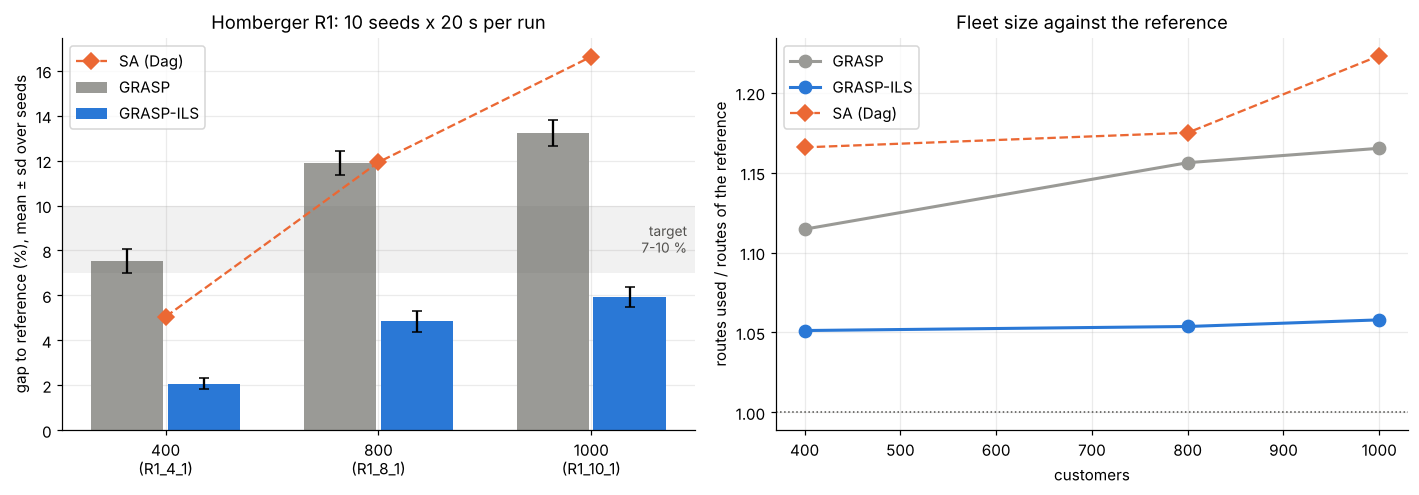

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
sizes = sorted(hb.n.unique())
x = np.arange(len(sizes))
for k, v in enumerate(["GRASP", "GRASP-ILS"]):
    s = hb_sum[hb_sum.label == v].sort_values("n")
    ax.bar(x + (k - 0.5) * 0.36, s.mean_gap, 0.34, yerr=s.sd_gap, capsize=3,
           color=VARIANT_COLOR[v], label=v)
ax.plot(x, SA_HOMBERGER.set_index("n").loc[sizes, "SA mean gap"], "D--", color="#eb6834",
        ms=7, lw=1.5, label="SA (Dag)")
ax.axhspan(7, 10, color="#52514e", alpha=0.08, lw=0)
ax.text(x[-1] + 0.45, 8.5, "target\n7-10 %", va="center", ha="right", fontsize=9, color="#52514e")
ax.set_xticks(x, [f"{n}\n({i})" for n, i in zip(sizes, L.HOMBERGER)])
ax.set_ylabel("gap to reference (%), mean ± sd over seeds")
ax.set_title("Homberger R1: 10 seeds x 20 s per run"); ax.legend(loc="upper left")

ax = axes[1]
for v in ["GRASP", "GRASP-ILS"]:
    s = hb_sum[hb_sum.label == v].sort_values("n")
    ax.plot(s.n, s.routes / s.ref_routes, "o-", lw=2, ms=8, color=VARIANT_COLOR[v], label=v)
ax.plot(SA_HOMBERGER.n, SA_HOMBERGER["SA routes"] / hb_refs.reference_routes.values, "D--",
        color="#eb6834", ms=7, lw=1.5, label="SA (Dag)")
ax.axhline(1, color="#52514e", lw=1, ls=":")
ax.set_xlabel("customers"); ax.set_ylabel("routes used / routes of the reference")
ax.set_title("Fleet size against the reference"); ax.legend()
plt.tight_layout(); plt.show()

R1_10_1, GRASP-ILS, seed 1: 55821.1 vs reference 53026.1 (gap 5.27 %), 102 routes, 2 starts, 531 kicks in 20.0 s


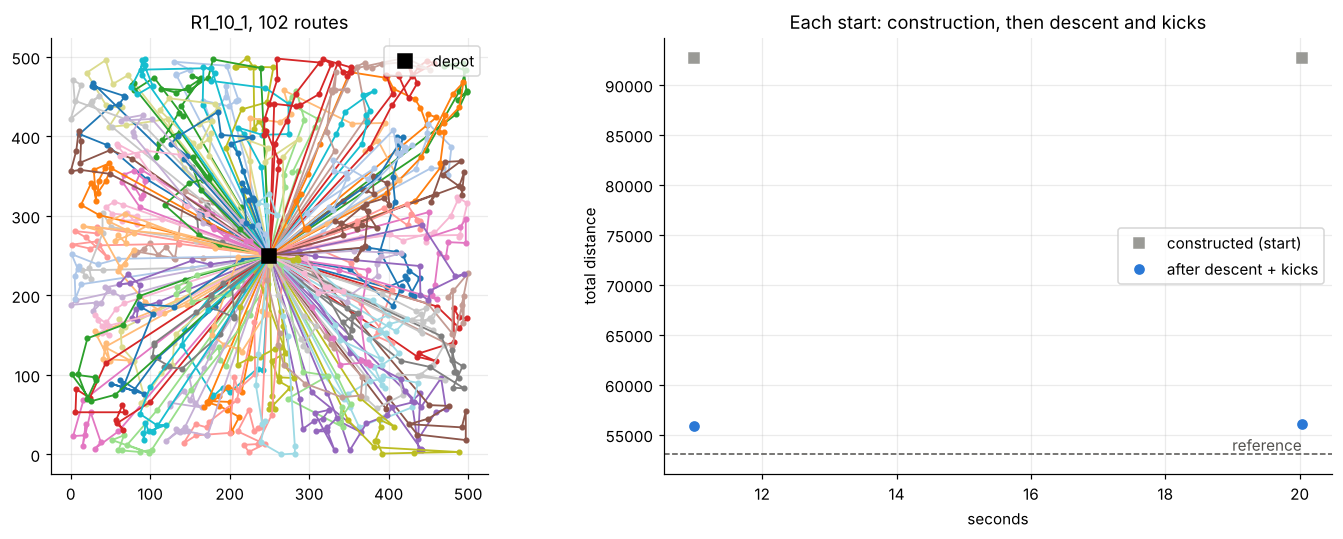

In [6]:
# Convergence of one GRASP-ILS run on the largest instance (seed 1), with its route map.
inst_big = homberger.load("R1_10_1")
res_big = grasp(inst_big, GRASPParams(iterations=10**9, time_limit=LARGE_LIMIT,
                                      **L.LARGE["GRASP-ILS"]), seed=1)
h = pd.DataFrame(res_big.history)
print(f"R1_10_1, GRASP-ILS, seed 1: {res_big.cost:.1f} vs reference {inst_big.best_known} "
      f"(gap {gap_percent(res_big.cost, inst_big.best_known):.2f} %), {len(res_big.best)} routes, "
      f"{res_big.iterations} starts, {h.kicks.iloc[-1]} kicks in {res_big.runtime:.1f} s")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_routes(inst_big, res_big.best, ax=axes[0])
axes[0].set_title(f"R1_10_1, {len(res_big.best)} routes")
axes[1].plot(h.seconds, h.constructed, "s", color="#9a9a96", ms=6, label="constructed (start)")
axes[1].plot(h.seconds, h.after_ls, "o", color=VARIANT_COLOR["GRASP-ILS"], ms=6,
             label="after descent + kicks")
axes[1].axhline(inst_big.best_known, ls="--", lw=1, color="#52514e")
axes[1].annotate("reference", (h.seconds.max(), inst_big.best_known), ha="right", va="bottom",
                 color="#52514e")
axes[1].set_xlabel("seconds"); axes[1].set_ylabel("total distance")
axes[1].set_title("Each start: construction, then descent and kicks"); axes[1].legend()
plt.tight_layout(); plt.show()


### 10.1 Analysis: Homberger

* **Target met.** GRASP-ILS has a mean gap of **2.08 %, 4.85 % and 5.93 %** at 400, 800 and
  1,000 customers. All 30 runs are at or under 7 %; the worst is 6.72 % (`R1_10_1`, seed 4). Seeds
  barely matter: the standard deviation is 0.26 to 0.47 points.
* **Plain GRASP does not reach it.** Without kicks the gap is 7.5 %, 11.9 % and 13.2 %, even with
  61, 13 and 8 starts. Restarting from a new randomized construction is a weak way to spend time
  on large instances: at $n = 1{,}000$ each start costs 2.5 s and its construction lands about 75 % above
  the reference before the descent. Improving one good solution locally (about 470 to 1,130 kicks per
  run) pays off far more. This matches the Solomon tuning (section 6.1), where GRASP-ILS also won,
  but here the difference is much larger (7 to 8 gap points instead of about 1).
* **Against SA (Dag, same protocol).** GRASP-ILS is lower at every size: 2.08 vs 5.05 %, 4.85 vs
  11.93 % and 5.93 vs 16.63 %. Its gap also grows much more slowly with $n$: about +4 points from
  400 to 1,000 customers, against about +12 for SA.
* **Fleet.** The objective is distance only, but shorter routes go together with fewer trucks:
  GRASP-ILS uses only 5-6 % more routes than the reference (43 / 84 / 100.5 vs 41 / 80 / 95),
  against 16-22 % for SA and 11-17 % for plain GRASP. Most of the remaining gap is linked to
  these extra trucks (each one adds two depot legs), because the reference solutions minimize the
  fleet first.
* **Time budget.** Plain GRASP slightly overruns 20 s at $n = 1{,}000$ (up to 22 s), because the
  time limit is not checked inside the construction. GRASP-ILS stays within 20.3 s, because the
  localized descent checks the limit.
* **What made the difference.** The one-factor study on `R1_4_1` (section 13, intrinsic, 400 customers) separates
  the three ingredients: the kicks per start matter most (7.6 % with no kicks, 2.2 % with 300),
  then the kick size, then the type of descent.


## 11. 10,000 customers: Dag's synthetic NetworkX graph

Same instance as section 11 of Dag's SA notebook: 10,000 customers uniform on $[0, 100]^2$, depot
at (50, 50), demands 1-10, capacity 100, graph seed 101, complete Euclidean distances (0.8 GB in
float64). `L.synthetic()` reproduces his generator; the check below verifies that his sweep start
has exactly the cost he reports (189,072.08). There is no known optimum, so, as Dag does, we
report the improvement over that sweep solution, and we compare the final distances.

**What changes at this size.** The insertion heuristics of section 4 are $O(n^2)$ per start or
worse (the regret scan is about $O(n^3)$ here), far too slow for 10,000 customers. For this
instance GRASP uses `construction="nearest"`: randomized nearest-neighbor route building over the
20-nearest-neighbor lists (RCL with the same $\alpha$), $O(nk)$, about 0.2 s. The neighbor lists
are built by partial sorting (`np.argpartition`), and the descent is the localized one of
section 10. Above 2,000 customers `_Model` stores the matrix as one typed `array('d')` per row (0.8 GB,
like the numpy matrix, instead of about 3.2 GB as Python lists). It is built once (about 10 s,
before the timer starts, like Dag's instance generation) and shared by the runs (`model=`).
Expect about 2 GB of RAM for this section.

**Budget.** 60 s per run, about the 59.6 s of Dag's untimed 10-million-move SA run. Three seeds.

In [7]:
big = L.synthetic(10_000, "uniform", 100.0, 101)
big_sweep = L.sweep(big)
assert abs(big_sweep.cost(big) - 189072.07597) < 1e-3, "not the same instance as Dag's"
print(f"{big.name}: {big.n_customers} customers, sweep start {big_sweep.cost(big):,.2f} with "
      f"{len(big_sweep)} routes, lower bound on routes ceil(sum q / Q) = "
      f"{int(np.ceil(big.demands.sum() / big.capacity))}")

BIG_LIMIT = 5.0 if QUICK_CHECK else 60.0
BIG_SEEDS = (1,) if QUICK_CHECK else (1, 2, 3)
BIG_PARAMS = dict(L.LARGE["GRASP-ILS"], construction="nearest")
big_model = G._Model(big, 20)       # built once and shared by the runs below (not timed)


def grasp_on_model(model, inst, params, seed, limit):
    # grasp() reusing the prebuilt _Model of the instance (model= argument).
    return grasp(inst, GRASPParams(iterations=10**9, time_limit=limit, **params), seed=seed,
                 model=model)


big_csv = RESULTS / f"grasp_synthetic_10000{LARGE_TAG}.csv"
big_hist_csv = RESULTS / f"grasp_synthetic_10000_history{LARGE_TAG}.csv"
if RECOMPUTE_LARGE or not big_csv.exists():
    rows, hist = [], []
    for seed in BIG_SEEDS:
        r = grasp_on_model(big_model, big, BIG_PARAMS, seed, BIG_LIMIT)
        assert r.best.is_feasible(big)
        loads = np.array([big.demands[rt].sum() for rt in r.best.routes])
        rows.append(dict(seed=seed, cost=r.cost, routes=len(r.best), starts=r.iterations,
                         kicks=r.history[-1]["kicks"], seconds=r.runtime,
                         first_construction=r.history[0]["constructed"],
                         mean_load_pct=100 * loads.mean() / big.capacity))
        hist += [dict(h, seed=seed) for h in r.history]
        if seed == BIG_SEEDS[0]:
            big_best = r.best
    big_runs, big_hist = pd.DataFrame(rows), pd.DataFrame(hist)
    big_runs.to_csv(big_csv, index=False); big_hist.to_csv(big_hist_csv, index=False)
else:
    big_runs, big_hist = pd.read_csv(big_csv), pd.read_csv(big_hist_csv)
    big_best = grasp_on_model(big_model, big, BIG_PARAMS, BIG_SEEDS[0], BIG_LIMIT).best
big_runs["improvement_over_sweep_pct"] = 100 * (1 - big_runs.cost / big_sweep.cost(big))
display(big_runs.round(2))

nx-uniform-n10000-q100-g101: 10000 customers, sweep start 189,072.08 with 569 routes, lower bound on routes ceil(sum q / Q) = 553


,seed,cost,routes,starts,kicks,seconds,first_construction,mean_load_pct,improvement_over_sweep_pct
0,1,48875.27,555,3,637,60.17,52494.95,99.6,74.15
1,2,48791.89,555,3,654,60.03,52694.16,99.6,74.19
2,3,48941.72,555,3,621,60.07,52616.14,99.6,74.11


In [8]:
# Side by side with Dag's SA run on the same instance (notebooks/SA.ipynb, section 11.1).
SA_BIG = dict(cost=119173.682498, routes=672, seconds=59.638, start="sweep", moves="10,000,000")
cmp_big = pd.DataFrame([
    {"method": "sweep start (common reference)", "distance": big_sweep.cost(big),
     "routes": len(big_sweep), "seconds": np.nan},
    {"method": "SA, seed 1 (Dag), from the sweep", "distance": SA_BIG["cost"],
     "routes": SA_BIG["routes"], "seconds": SA_BIG["seconds"]},
    {"method": f"GRASP-ILS, mean of {len(big_runs)} seeds", "distance": big_runs.cost.mean(),
     "routes": big_runs.routes.mean(), "seconds": big_runs.seconds.mean()},
    {"method": "GRASP-ILS, best seed", "distance": big_runs.cost.min(),
     "routes": big_runs.loc[big_runs.cost.idxmin(), "routes"],
     "seconds": big_runs.loc[big_runs.cost.idxmin(), "seconds"]},
])
cmp_big["improvement over sweep (%)"] = 100 * (1 - cmp_big.distance / big_sweep.cost(big))
display(cmp_big.round(2))

# Same start as SA: apply only the GRASP descent to Dag's sweep solution (no construction).
import random
st = G._State(big_model, [list(r) for r in big_sweep.routes])
t = time.perf_counter()
G._LocalSearch(big_model, st, random.Random(1), GRASPParams(**BIG_PARAMS)).run_local(None, None)
sweep_ls = st.to_solution()
assert sweep_ls.is_feasible(big)
print(f"GRASP descent alone from the sweep start: {sweep_ls.cost(big):,.1f} "
      f"({100 * (1 - sweep_ls.cost(big) / big_sweep.cost(big)):.1f} % better than the sweep, "
      f"{len(sweep_ls)} routes, {time.perf_counter() - t:.1f} s)")

,method,distance,routes,seconds,improvement over sweep (%)
0,sweep start (common reference),189072.08,569.0,NaN,0.00
1,"SA, seed 1 (Dag), from the sweep",119173.68,672.0,59.64,36.97
2,"GRASP-ILS, mean of 3 seeds",48869.63,555.0,60.09,74.15
3,"GRASP-ILS, best seed",48791.89,555.0,60.03,74.19


GRASP descent alone from the sweep start: 51,044.6 (73.0 % better than the sweep, 561 routes, 13.2 s)


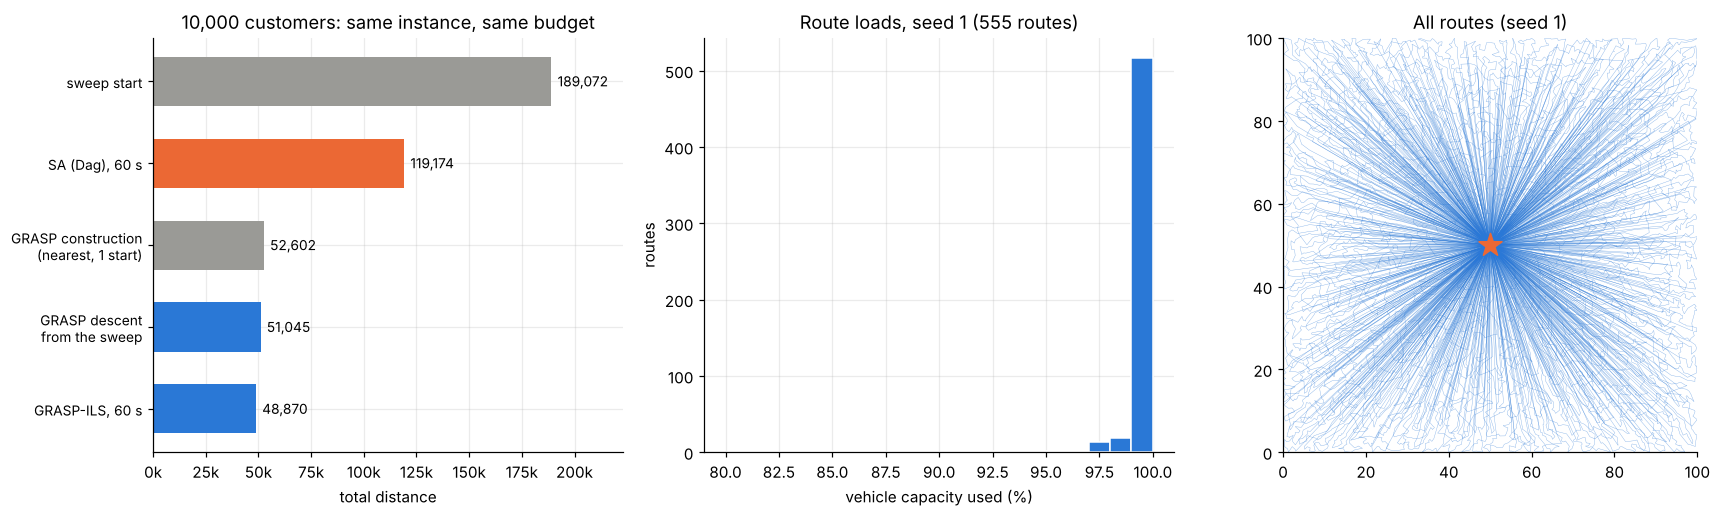

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
steps = [("sweep start", big_sweep.cost(big), "#9a9a96"),
         ("SA (Dag), 60 s", SA_BIG["cost"], "#eb6834"),
         ("GRASP construction\n(nearest, 1 start)", big_runs.first_construction.mean(), "#9a9a96"),
         ("GRASP descent\nfrom the sweep", sweep_ls.cost(big), "#2a78d6"),
         ("GRASP-ILS, 60 s", big_runs.cost.mean(), "#2a78d6")]
ax.barh(range(len(steps)), [v for _, v, _ in steps], 0.6, color=[c for *_, c in steps])
for i, (_, v, _) in enumerate(steps):
    ax.annotate(f"{v:,.0f}", (v, i), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=9)
ax.set_yticks(range(len(steps)), [t for t, *_ in steps], fontsize=9); ax.invert_yaxis()
ax.set_xlim(0, big_sweep.cost(big) * 1.18)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.set_xlabel("total distance"); ax.set_title("10,000 customers: same instance, same budget")

loads = np.array([big.demands[r].sum() for r in big_best.routes]) / big.capacity * 100
axes[1].hist(loads, bins=np.linspace(80, 100, 21), color="#2a78d6", edgecolor="white")
axes[1].set_xlabel("vehicle capacity used (%)"); axes[1].set_ylabel("routes")
axes[1].set_title(f"Route loads, seed {BIG_SEEDS[0]} ({len(big_best)} routes)")

from matplotlib.collections import LineCollection
segs = []
for r in big_best.routes:
    pts = big.coords[[0, *r, 0]]
    segs += list(zip(pts[:-1], pts[1:]))
axes[2].add_collection(LineCollection(segs, lw=0.25, color="#2a78d6", alpha=0.6))
axes[2].scatter(*big.coords[0], marker="*", s=250, color="#eb6834", zorder=3)
axes[2].set(xlim=(0, 100), ylim=(0, 100), aspect="equal", title="All routes (seed 1)")
axes[2].grid(False)
plt.tight_layout(); plt.show()
del big_model  # free the 0.8 GB copy


### 11.1 Analysis: 10,000 customers

* **Same instance, same budget.** The sweep start reproduces Dag's 189,072.08 exactly, and every
  GRASP solution passes the shared `Solution.is_feasible` check.
* **Result.** In 60 s GRASP-ILS reaches **48,870** on average over three seeds, with very
  little spread (48,792 to 48,942). That is 74.2 % below the sweep start. Dag's SA ends at
  119,174 (37.0 % below the sweep) in the same time. GRASP uses 555 routes, at most 2 above the
  capacity lower bound of 553 (loads average 99.6 % of $Q$). SA uses 672.
* **Where the difference comes from.** The randomized nearest-neighbor construction alone
  already costs about 52,600: much better than the sweep, because routes follow nearby customers
  instead of thin angular slices that stretch from the depot to the border. To compare the
  improvement phases on equal terms, the GRASP descent was also run **from Dag's sweep solution**.
  It reaches 51,045 in about 12 s, so a better start explains only part of the gap. The granular
  neighborhoods do the rest: inter-route moves restricted to the 20 nearest neighbors, plus
  2-opt* and Or-opt. Each move is evaluated in $O(1)$ and is almost always useful. SA instead spends
  most of its 10 million proposals on random moves that are rejected.
* **Scaling.** At this size about 3 GRASP starts and 620-650 kicks fit in 60 s; one kick (30
  customers) costs about 0.1 s. The extra cost of 10,000 customers is in preprocessing: the
  distance matrix and the neighbor lists take about 10 s, outside the timer as for Dag.
* **Caveat.** This is a single instance with no known optimum and a uniform layout. The
  comparison says that GRASP-ILS is far better than SA *with these settings and this budget*, not
  that the gap would stay the same if SA had a better start or a longer budget.


## 12. Real road networks: Paris and São Paulo

Instances built with `cvrp.cities.load_city` from the RRNCO dataset (Son et al., ICLR 2026): 1,000
real addresses per city with OSRM road distances (km) and free-flow durations (min). The matrices
are **asymmetric** (one-way streets), which is why the intra-route 2-opt now adds the length
difference of the reversed segment (forward vs backward), exact on asymmetric matrices and
unchanged on symmetric ones. Depot = road medoid of the city, demands 1-10, capacity 100, the same
customer sample (seed 0) for every run of a size.

**Protocol.** $n \in \{100, 250, 500, 999\}$, objective = road km (CVRP), both variants of section
10, seeds 1-5, 20 s per run (80 runs). There is no best known solution for these instances, so the
quality measure is the **gap to the best distance found for that instance over all runs**, and the
comparison between cities uses **km per customer**.

The files are git-ignored: put `Paris_data.npz` and `Sao_Paulo_data.npz` in `data/cities/`
(download link in `data/README.md`).

In [10]:
# What the two road networks look like (full 1,000-point files).
from cvrp.cities import central_node


def haversine_km(pts):
    lat, lon = np.radians(pts[:, 0])[:, None], np.radians(pts[:, 1])[:, None]
    a = (np.sin((lat - lat.T) / 2) ** 2
         + np.cos(lat) * np.cos(lat.T) * np.sin((lon - lon.T) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


city_rows = []
for cname, path in L.CITY_FILES.items():
    raw = np.load(path)
    dkm, dmin, pts = raw["distance"], raw["duration"], raw["points"]
    off = ~np.eye(len(dkm), dtype=bool) & (dkm > 0) & (dkm.T > 0)  # a few points share a node
    crow = haversine_km(pts)
    dep = central_node(dkm)
    city_rows.append({
        "city": cname,
        "mean road km between points": dkm[off].mean(),
        "mean km depot -> customer": dkm[dep][off[dep]].mean(),
        "detour factor (road / straight line)": np.median(dkm[off] / np.maximum(crow[off], 1e-6)),
        "asymmetry |d_ij - d_ji| / d_ij (%)": 100 * np.median(np.abs(dkm - dkm.T)[off] / dkm[off]),
        "mean free-flow speed (km/h)": 60 * dkm[off].sum() / dmin[off].sum(),
    })
city_profile = pd.DataFrame(city_rows).set_index("city").T
display(city_profile.round(2))

city,Paris,Sao Paulo
mean road km between points,2.49,2.62
mean km depot -> customer,1.69,1.97
detour factor (road / straight line),1.51,1.65
asymmetry |d_ij - d_ji| / d_ij (%),17.39,20.62
mean free-flow speed (km/h),20.53,31.57


In [11]:
CITY_SIZES = (100, 250) if QUICK_CHECK else (100, 250, 500, 999)
cities = run_or_load("cities", L.city_jobs(sizes=CITY_SIZES,
                                           seeds=range(1, 3) if QUICK_CHECK else range(1, 6),
                                           limit=LARGE_LIMIT))
cities["city"] = cities["name"]
cities["best_found"] = cities.groupby("instance").distance.transform("min")
cities["gap_best_found"] = 100 * (cities.distance / cities.best_found - 1)
cities["km_per_customer"] = cities.distance / cities.n
cities["improvement_over_construction"] = 100 * (1 - cities.distance / cities.constructed)

city_sum = (cities.groupby(["city", "n", "label"])
              .agg(mean_km=("distance", "mean"), sd_km=("distance", "std"),
                   km_per_customer=("km_per_customer", "mean"),
                   gap_best_found=("gap_best_found", "mean"),
                   routes=("routes", "mean"), min_routes=("min_routes", "first"),
                   starts=("iterations", "mean"), kicks=("kicks", "mean"),
                   improvement_pct=("improvement_over_construction", "mean"))
              .reset_index())
display(city_sum.round(2))

,city,n,label,mean_km,sd_km,km_per_customer,gap_best_found,routes,min_routes,starts,kicks,improvement_pct
0,Paris,100,GRASP,55.64,0.21,0.56,2.39,6.0,6,1074.0,0.0,22.23
1,Paris,100,GRASP-ILS,54.34,0.00,0.54,0.00,6.0,6,25.2,7387.8,24.05
2,Paris,250,GRASP,112.58,1.08,0.45,12.17,14.0,14,202.4,0.0,20.96
3,Paris,250,GRASP-ILS,100.85,0.46,0.40,0.49,14.6,14,8.4,2389.2,29.19
4,Paris,500,GRASP,193.53,1.77,0.39,12.13,29.0,29,34.8,0.0,27.91
5,Paris,500,GRASP-ILS,175.08,1.66,0.35,1.44,29.0,29,3.6,893.2,34.79
6,Paris,999,GRASP,367.47,4.27,0.37,20.13,57.0,57,6.8,0.0,24.64
7,Paris,999,GRASP-ILS,313.19,4.32,0.31,2.39,58.0,57,2.0,480.6,35.76
8,Sao Paulo,100,GRASP,65.59,0.51,0.66,4.86,6.0,6,887.8,0.0,25.21
9,Sao Paulo,100,GRASP-ILS,62.86,0.40,0.63,0.49,6.0,6,23.6,7001.0,28.33


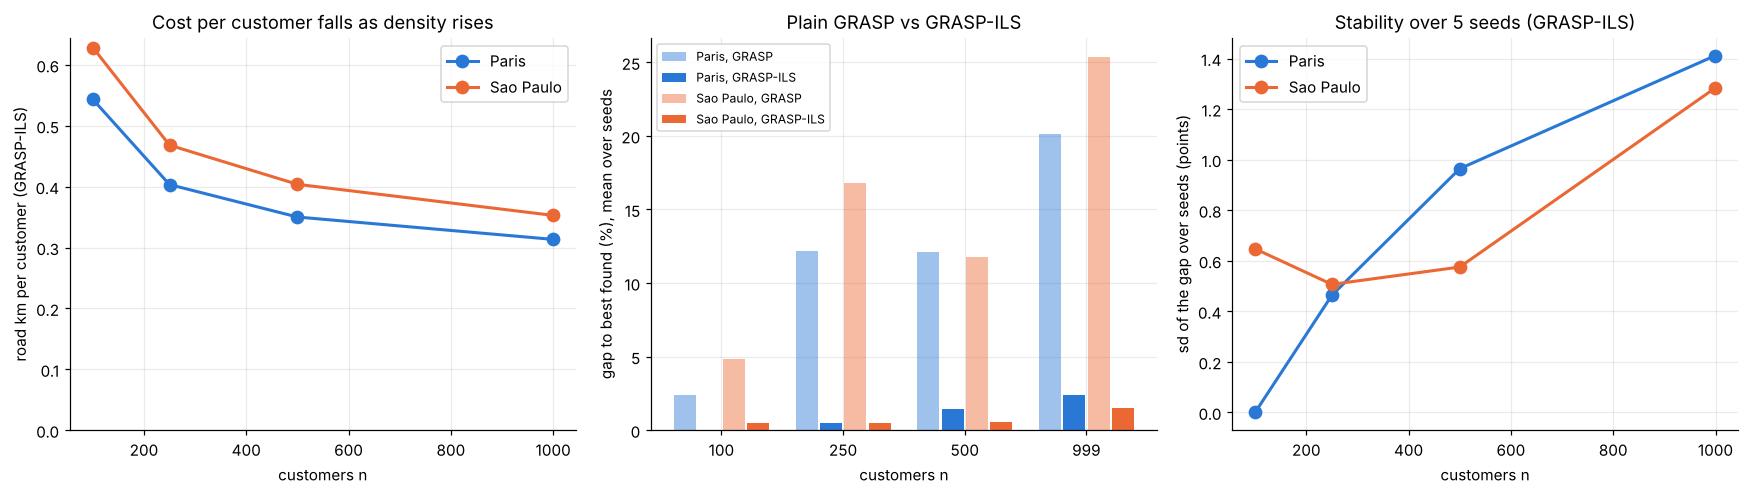

In [12]:
CITY_COLOR = {"Paris": "#2a78d6", "Sao Paulo": "#eb6834"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ils_c = city_sum[city_sum.label == "GRASP-ILS"]
for cname, g in ils_c.groupby("city"):
    axes[0].plot(g.n, g.km_per_customer, "o-", lw=2, ms=8, color=CITY_COLOR[cname], label=cname)
axes[0].set_xlabel("customers n"); axes[0].set_ylabel("road km per customer (GRASP-ILS)")
axes[0].set_title("Cost per customer falls as density rises"); axes[0].legend()
axes[0].set_ylim(0, None)

sizes = sorted(city_sum.n.unique())
x = np.arange(len(sizes))
for k, (cname, v) in enumerate([(c, v) for c in CITY_COLOR for v in ("GRASP", "GRASP-ILS")]):
    g = city_sum[(city_sum.city == cname) & (city_sum.label == v)].sort_values("n")
    axes[1].bar(x + (k - 1.5) * 0.2, g.gap_best_found, 0.18, color=CITY_COLOR[cname],
                alpha=1.0 if v == "GRASP-ILS" else 0.45,
                label=f"{cname}, {v}")
axes[1].set_xticks(x, sizes); axes[1].set_xlabel("customers n")
axes[1].set_ylabel("gap to best found (%), mean over seeds")
axes[1].set_title("Plain GRASP vs GRASP-ILS"); axes[1].legend(fontsize=8)

sd = cities[cities.label == "GRASP-ILS"].groupby(["city", "n"]).gap_best_found.std().unstack(0)
for cname in CITY_COLOR:
    axes[2].plot(sd.index, sd[cname], "o-", lw=2, ms=8, color=CITY_COLOR[cname], label=cname)
axes[2].set_xlabel("customers n"); axes[2].set_ylabel("sd of the gap over seeds (points)")
axes[2].set_title("Stability over 5 seeds (GRASP-ILS)"); axes[2].legend()
plt.tight_layout(); plt.show()

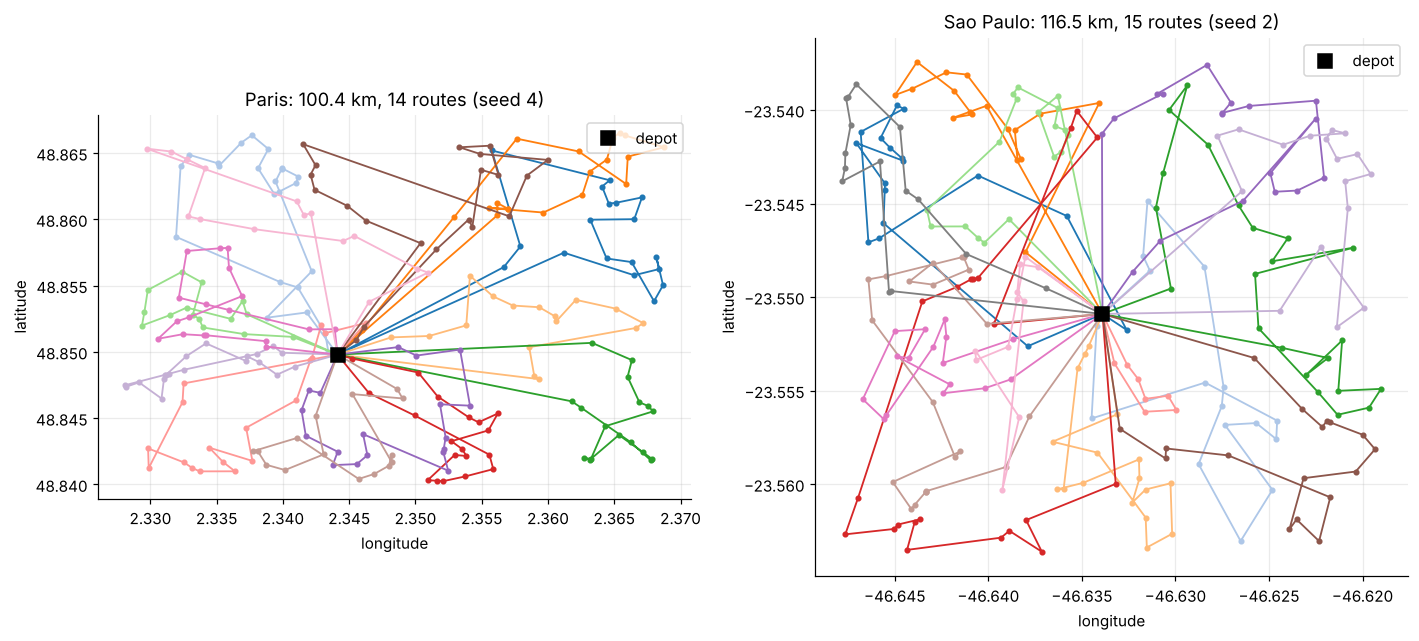

In [13]:
# Route maps, 250 customers, best GRASP-ILS seed of each city (straight lines between stops;
# the cost is the road distance).
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, cname in zip(axes, CITY_COLOR):
    inst_c = L.city(cname, 250)
    sub = cities[(cities.city == cname) & (cities.n == 250) & (cities.label == "GRASP-ILS")]
    seed = int(sub.loc[sub.distance.idxmin(), "seed"])
    r = grasp(inst_c, GRASPParams(iterations=10**9, time_limit=LARGE_LIMIT,
                                  **L.LARGE["GRASP-ILS"]), seed=seed)
    plot_routes(inst_c, r.best, ax=ax)
    ax.set_title(f"{cname}: {r.cost:.1f} km, {len(r.best)} routes (seed {seed})")
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
plt.tight_layout(); plt.show()

In [14]:
# Paris vs São Paulo, same n, same protocol: paired by (n, seed, variant).
pair_c = cities.pivot_table(index=["n", "label", "seed"], columns="city",
                            values="km_per_customer").dropna()
ratio = (pair_c["Sao Paulo"] / pair_c["Paris"]).groupby(level=[0, 1]).mean().unstack()
display((ratio).round(3).rename_axis(columns="Sao Paulo / Paris, km per customer"))
w = stats.wilcoxon(pair_c["Sao Paulo"], pair_c["Paris"])
print(f"Sao Paulo needs {100 * (ratio.values.mean() - 1):.0f} % more road km per customer than "
      f"Paris on average (Wilcoxon over {len(pair_c)} paired runs: p = {w.pvalue:.2g}).")
g_city = cities.groupby(["city", "label"]).gap_best_found.mean().unstack()
display(g_city.round(2).rename_axis(columns="mean gap to best found (%)"))

"Sao Paulo / Paris, km per customer",GRASP,GRASP-ILS
n,,
100,1.18,1.16
250,1.21,1.16
500,1.16,1.15
999,1.19,1.13


Sao Paulo needs 17 % more road km per customer than Paris on average (Wilcoxon over 40 paired runs: p = 3.6e-08).


mean gap to best found (%),GRASP,GRASP-ILS
city,,
Paris,11.71,1.08
Sao Paulo,14.71,0.75



### 12.1 Analysis: Paris vs São Paulo

**The cities.** The two 1,000-point samples are very different road networks. In São Paulo the
roads are longer relative to the straight line: median detour factor 1.65, against 1.51 in Paris.
Customers are also farther from the central depot (1.97 km against 1.69 km on average), and its
matrix is more asymmetric: going and returning between two points differ by about 21 % in median
(17 % in Paris), because of one-way streets and arterial roads. São Paulo's free-flow speed is higher
(about 32 km/h against 21 km/h), so the gap in minutes is smaller than the gap in kilometers.

**GRASP on both cities.**
* **São Paulo costs more.** For the same $n$ and the same protocol, São Paulo needs **13-21 %
  more road km per customer** (17 % on average). The difference holds at every size, for both
  variants and for all 40 paired runs (Wilcoxon $p \approx 4 \cdot 10^{-8}$). It follows the
  city profile above: longer detours and customers farther from the depot.
* **Economy of density.** Cost per customer falls as $n$ grows: from 0.54 to 0.31 km in Paris and
  from 0.63 to 0.35 km in São Paulo with GRASP-ILS, because more customers in the same area means
  shorter hops between them. The depot legs are shared by more stops.
* **GRASP-ILS is again essential.** Plain GRASP is about 12-25 % above the best solution found at
  $n \geq 250$, against 0.5-2.4 % for GRASP-ILS. The difference grows with $n$, as on Homberger.
  Plain GRASP is a little worse in São Paulo (14.7 % against 11.7 % on average), consistent with
  a harder network: there the descent removes 25-31 % of the constructed distance, against
  21-28 % in Paris, so the greedy constructions are further from good solutions.
* **Fleet.** Both cities need the minimum number of trucks given by capacity (6 / 14 / 29 / 57
  routes); GRASP-ILS sometimes uses one more at $n = 250$ and $999$ when that shortens the
  total distance.
* **Stability.** Seed-to-seed spread stays below 1.5 gap points and grows with $n$, because
  fewer starts and kicks fit in 20 s on larger instances (2 starts and about 500 kicks at
  $n = 999$, against 25 starts and 7,000 kicks at $n = 100$).

The route maps draw straight lines between stops, but the cost is the road distance. That is why
some routes look crossed: on real roads the straight-line picture is misleading, especially with
one-way streets.


## 13. Sensitivity: intrinsic and extrinsic variables

The professor asked us to vary the **intrinsic** and the **extrinsic** variables and compare the
results each time.

* **Intrinsic variables** are the parameters *of the algorithm*, which we choose: RCL greediness
  $\alpha$, kicks per start, size of the neighbor lists, first vs best improvement, construction
  score, type of descent, time budget, kick size.
* **Extrinsic variables** are properties *of the instance and of its environment*, which we do not
  choose: number of customers, vehicle capacity, time-window width, traffic (departure hour),
  spatial layout of the customers, road network (city).

**Protocol: one factor at a time.** Every other variable stays at its reference value.

| Study | Instances | Reference setting | Seeds | Budget |
|---|---|---|---|---|
| Intrinsic, Solomon | the 6 tuning instances (C101, C201, R101, R201, RC101, RC201), so the test set of section 7 stays clean | tuned setting of section 6 ($\alpha$ = 0.3, first improvement, 90 kicks, regret, 20 neighbors, VND) | 101, 102 | 10 s |
| Intrinsic, large | Homberger `R1_4_1` (400 customers) | large setting of section 10 | 1-3 | 20 s |
| Extrinsic | Paris (road km or minutes), synthetic layouts | GRASP-ILS large setting | 1-3 | 10 s |

Intrinsic results are measured by the **gap to the BKS** (same instances, so the variable is the
only change). Extrinsic variables change the instance itself, so a gap is not comparable across
levels; we report **cost per customer**, routes against the capacity lower bound
$\lceil \sum q_i / Q \rceil$, the number of kicks that fit in the budget, and the **spread over
seeds** (coefficient of variation), which says how hard each instance is for GRASP.

,factor,value,reference,mean_gap,worst_gap,seed_sd,starts,kicks
0,alpha,0.0,False,1.54,4.28,0.00,19.50,1706.42
1,alpha,0.1,False,1.56,4.99,0.23,18.50,1622.17
2,alpha,0.3,True,1.24,4.90,0.03,18.50,1629.75
3,alpha,0.5,False,1.62,5.61,0.07,17.00,1477.50
4,alpha,1.0,False,0.82,2.56,0.09,16.75,1457.50
5,kicks per start,0,False,2.50,9.73,1.06,288.17,0.00
6,kicks per start,30,False,1.79,5.39,0.14,45.42,1346.33
7,kicks per start,90,True,1.24,4.90,0.03,18.50,1629.75
8,kicks per start,250,False,1.52,4.74,0.09,7.17,1684.00
9,neighbors,5,False,1.90,5.62,0.29,43.25,3857.33


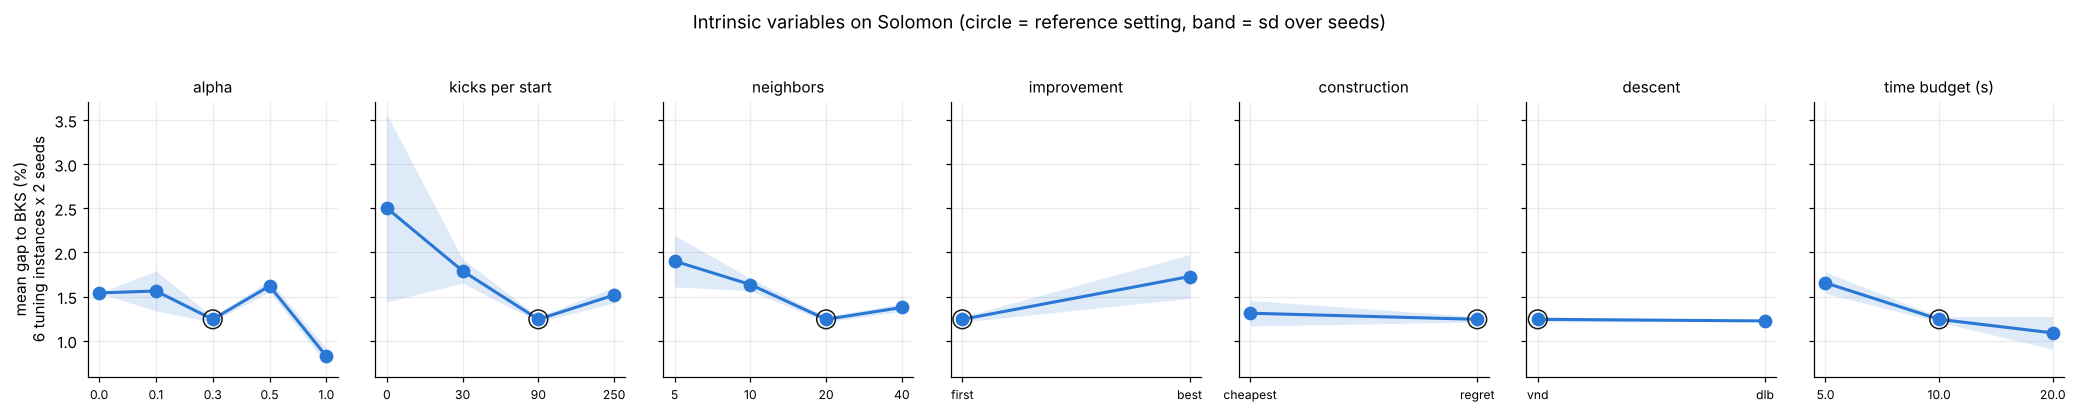

In [15]:
intr = L.label_split(run_or_load("intrinsic", L.intrinsic_jobs(
    seeds=(101,) if QUICK_CHECK else (101, 102))))
INTR_ORDER = {"alpha": "alpha", "perturb_kicks": "kicks per start", "n_neighbors": "neighbors",
              "improvement": "improvement", "construction": "construction",
              "local_search": "descent", "time_limit": "time budget (s)"}
BASE_VAL = {k: str(v) for k, v in L.INTRINSIC_BASE.items()} | {"time_limit": "10.0"}

# The reference setting appears once in the jobs; it is the reference level of every factor.
base_runs = intr[(intr.study == "intrinsic") & (intr.label == "alpha=0.3")]
rows = []
for f, vals in L.INTRINSIC.items():
    for v in vals:
        runs = intr[(intr.study == "intrinsic") & (intr.label == f"{f}={v}")]
        if runs.empty:
            runs = base_runs
        per_inst = runs.groupby("instance").gap.mean()
        rows.append({"factor": INTR_ORDER[f], "value": str(v),
                     "reference": str(v) == BASE_VAL[f], "mean_gap": runs.gap.mean(),
                     "worst_gap": runs.gap.max(),
                     "seed_sd": runs.groupby("seed").gap.mean().std(),
                     "starts": runs.iterations.mean(), "kicks": runs.kicks.mean()})
intr_tab = pd.DataFrame(rows)
display(intr_tab.round(2))

fig, axes = plt.subplots(1, len(L.INTRINSIC), figsize=(19, 3.6), sharey=True)
for ax, (f, name) in zip(axes, INTR_ORDER.items()):
    t = intr_tab[intr_tab.factor == name].reset_index(drop=True)
    ax.plot(range(len(t)), t.mean_gap, "o-", lw=2, ms=8, color="#2a78d6")
    ax.fill_between(range(len(t)), t.mean_gap - t.seed_sd, t.mean_gap + t.seed_sd,
                    color="#2a78d6", alpha=0.15, lw=0)
    ref = t.index[t.reference][0]
    ax.scatter([ref], [t.mean_gap[ref]], s=150, facecolor="none", edgecolor="#1a1a19", zorder=3)
    ax.set_xticks(range(len(t)), t.value, fontsize=8); ax.set_title(name, fontsize=10)
axes[0].set_ylabel("mean gap to BKS (%)\n6 tuning instances x 2 seeds")
fig.suptitle("Intrinsic variables on Solomon (circle = reference setting, band = sd over seeds)",
             y=1.03)
plt.tight_layout(); plt.show()

,factor,value,mean_gap,sd_gap,routes,starts,kicks
0,kick_max,15,2.54,0.32,43.00,8.00,2204.00
1,kick_max,30,2.22,0.13,43.00,4.00,1047.00
2,kick_max,60,2.87,0.24,42.67,2.67,600.33
3,kick_max,120,2.95,0.31,43.33,2.00,532.33
4,perturb_kicks,0,7.64,0.28,47.00,53.67,0.00
5,perturb_kicks,30,4.19,0.20,43.33,21.33,620.33
6,perturb_kicks,300,2.22,0.13,43.00,4.00,1080.00
7,perturb_kicks,3000,2.01,0.19,43.33,1.00,1178.67
8,local_search,vnd,2.54,0.32,43.67,1.00,202.33
9,local_search,dlb,2.22,0.13,43.00,4.00,1088.00


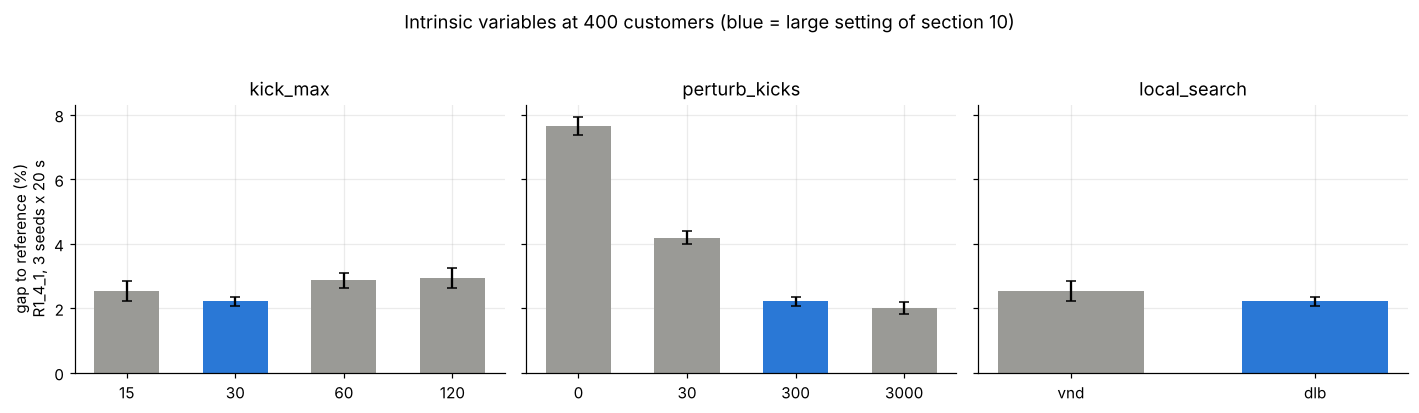

In [16]:
il = intr[intr.study == "intrinsic-large"]
il_tab = (il.groupby(["factor", "value"], sort=False)
            .agg(mean_gap=("gap", "mean"), sd_gap=("gap", "std"), routes=("routes", "mean"),
                 starts=("iterations", "mean"), kicks=("kicks", "mean")).reset_index())
display(il_tab.round(2))
LBASE = {"kick_max": "30", "perturb_kicks": "300", "local_search": "dlb"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, f in zip(axes, ["kick_max", "perturb_kicks", "local_search"]):
    t = il_tab[il_tab.factor == f].reset_index(drop=True)
    ax.bar(range(len(t)), t.mean_gap, 0.6, yerr=t.sd_gap, capsize=3,
           color=["#2a78d6" if v == LBASE[f] else "#9a9a96" for v in t.value])
    ax.set_xticks(range(len(t)), t.value); ax.set_title(f)
axes[0].set_ylabel("gap to reference (%)\nR1_4_1, 3 seeds x 20 s")
fig.suptitle("Intrinsic variables at 400 customers (blue = large setting of section 10)", y=1.03)
plt.tight_layout(); plt.show()

In [17]:
ext = L.label_split(run_or_load("extrinsic", L.extrinsic_jobs(
    seeds=(1,) if QUICK_CHECK else (1, 2, 3))))
ext.loc[ext.params.str.contains("duration"), "kicks"] = np.nan  # traffic mode does not count them
ext["cost_per_customer"] = ext.cost / ext.n
ext["routes_over_bound"] = ext.routes / ext.min_routes
ext_tab = (ext.groupby(["factor", "value"], sort=False)
             .agg(n=("n", "first"), cost=("cost", "mean"),
                  cost_per_customer=("cost_per_customer", "mean"),
                  cv_over_seeds_pct=("cost", lambda c: 100 * c.std() / c.mean()),
                  routes=("routes", "mean"), routes_over_bound=("routes_over_bound", "mean"),
                  starts=("iterations", "mean"), kicks=("kicks", "mean"),
                  distance_km=("distance", "mean"))
             .reset_index())
display(ext_tab.round(3))
print("Cost unit: road km (n, capacity, city), minutes (time windows, traffic), "
      "Euclidean units (layout).")

,factor,value,n,cost,cost_per_customer,cv_over_seeds_pct,routes,routes_over_bound,starts,kicks,distance_km
0,customers n,100,100,54.34,0.54,0.00,6.00,1.00,15.00,4257.00,54.34
1,customers n,250,250,101.37,0.41,0.62,14.33,1.02,4.33,1182.67,101.37
2,customers n,500,500,177.39,0.35,1.17,29.00,1.00,2.00,576.33,177.39
3,customers n,999,999,315.80,0.32,0.15,58.00,1.02,2.00,300.00,315.80
4,capacity Q,50,250,141.95,0.57,0.77,28.67,1.02,5.00,1313.67,141.95
5,capacity Q,100,250,101.37,0.41,0.62,14.33,1.02,4.67,1204.00,101.37
6,capacity Q,200,250,85.57,0.34,1.22,7.33,1.05,4.00,1034.67,85.57
7,time windows,none,250,311.19,1.25,0.87,15.00,1.07,4.67,1221.67,311.19
8,time windows,240 min,250,340.58,1.36,0.70,15.00,1.07,4.00,1026.33,340.58
9,time windows,120 min,250,421.54,1.69,0.99,15.00,1.07,3.67,911.67,421.54


Cost unit: road km (n, capacity, city), minutes (time windows, traffic), Euclidean units (layout).


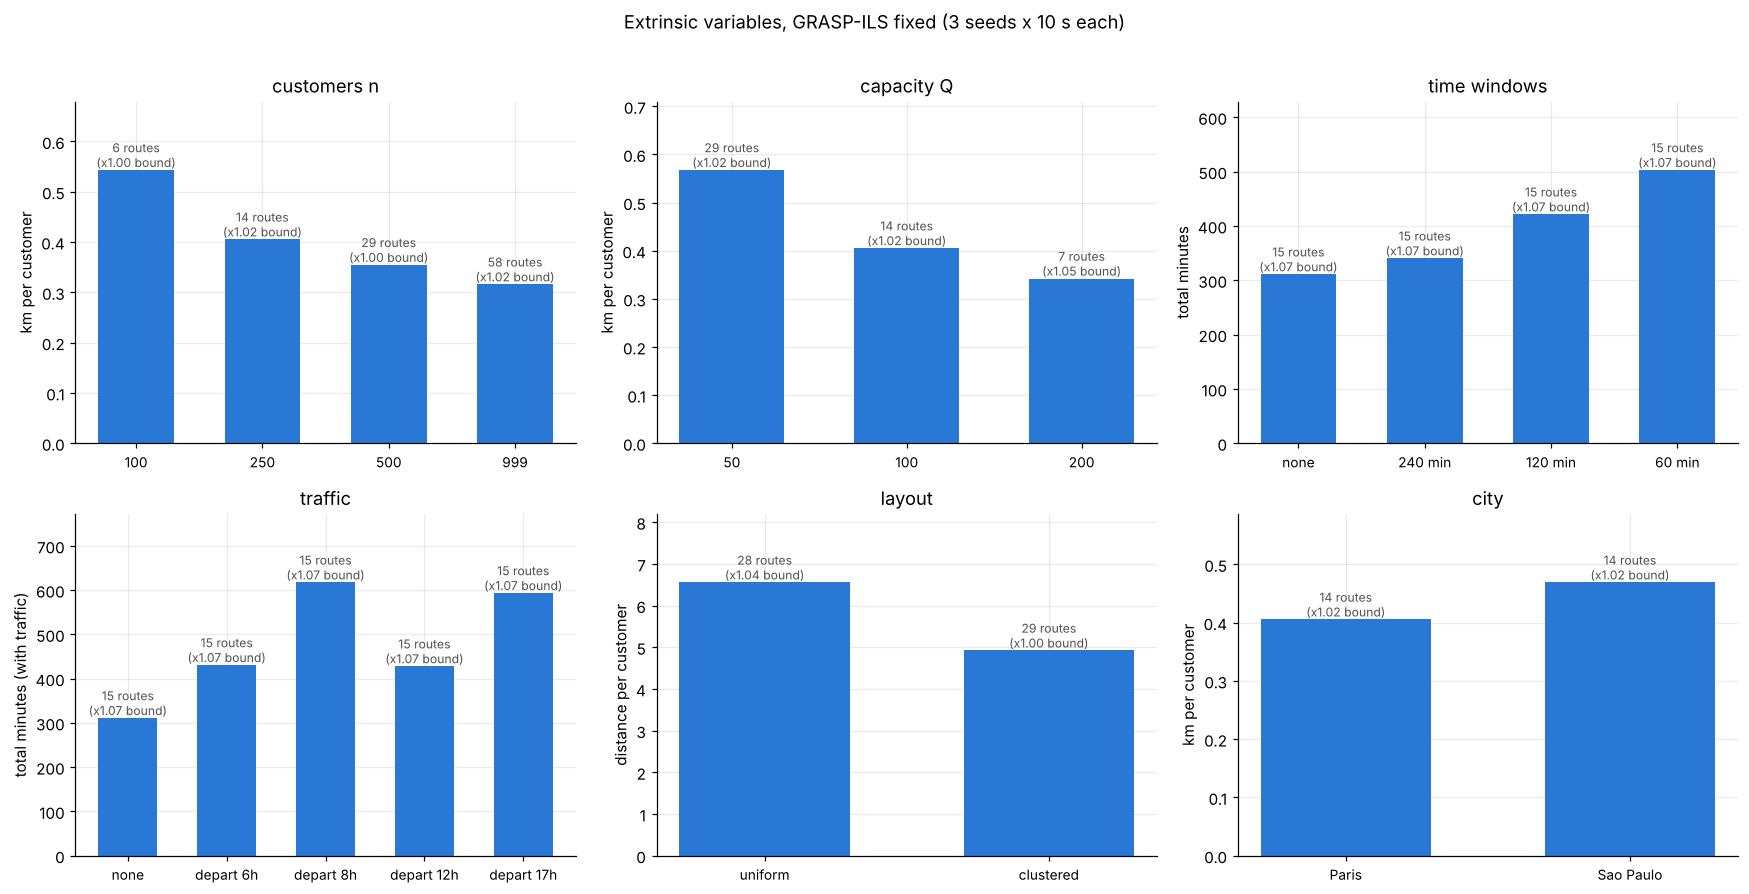

In [18]:
FACTORS = ["customers n", "capacity Q", "time windows", "traffic", "layout", "city"]
METRIC = {"customers n": ("cost_per_customer", "km per customer"),
          "capacity Q": ("cost_per_customer", "km per customer"),
          "time windows": ("cost", "total minutes"),
          "traffic": ("cost", "total minutes (with traffic)"),
          "layout": ("cost_per_customer", "distance per customer"),
          "city": ("cost_per_customer", "km per customer")}
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, f in zip(axes.flat, FACTORS):
    t = ext_tab[ext_tab.factor == f].reset_index(drop=True)
    col, lab = METRIC[f]
    ax.bar(range(len(t)), t[col], 0.6, color="#2a78d6")
    for i, rb in enumerate(t.routes_over_bound):
        ax.annotate(f"{t.routes[i]:.0f} routes\n(x{rb:.2f} bound)", (i, t[col][i]),
                    ha="center", va="bottom", fontsize=8, color="#52514e")
    ax.set_xticks(range(len(t)), t.value, fontsize=9)
    ax.set_title(f); ax.set_ylabel(lab); ax.set_ylim(0, t[col].max() * 1.25)
fig.suptitle("Extrinsic variables, GRASP-ILS fixed (3 seeds x 10 s each)", y=1.01)
plt.tight_layout(); plt.show()

In [19]:
# Which variables matter most? Effect size = relative range of the response over the levels.
eff = []
for name in INTR_ORDER.values():
    t = intr_tab[intr_tab.factor == name]
    eff.append({"kind": "intrinsic (Solomon)", "variable": name,
                "effect": t.mean_gap.max() - t.mean_gap.min(), "unit": "gap points",
                "best level": t.loc[t.mean_gap.idxmin(), "value"]})
for f in ["kick_max", "perturb_kicks", "local_search"]:
    t = il_tab[il_tab.factor == f]
    eff.append({"kind": "intrinsic (400 customers)", "variable": f,
                "effect": t.mean_gap.max() - t.mean_gap.min(), "unit": "gap points",
                "best level": t.loc[t.mean_gap.idxmin(), "value"]})
for f in FACTORS:
    t = ext_tab[ext_tab.factor == f]
    col = METRIC[f][0]
    eff.append({"kind": "extrinsic", "variable": f,
                "effect": 100 * (t[col].max() / t[col].min() - 1), "unit": "% change in cost",
                "best level": t.loc[t[col].idxmin(), "value"]})
effects = pd.DataFrame(eff).sort_values(["kind", "effect"], ascending=[True, False])
display(effects.round(2))

,kind,variable,effect,unit,best level
13,extrinsic,traffic,98.46,% change in cost,none
10,extrinsic,customers n,71.90,% change in cost,999
11,extrinsic,capacity Q,65.89,% change in cost,200
12,extrinsic,time windows,61.67,% change in cost,none
14,extrinsic,layout,33.16,% change in cost,clustered
15,extrinsic,city,15.69,% change in cost,Paris
8,intrinsic (400 customers),perturb_kicks,5.63,gap points,3000
7,intrinsic (400 customers),kick_max,0.73,gap points,30
9,intrinsic (400 customers),local_search,0.33,gap points,dlb
1,intrinsic (Solomon),kicks per start,1.26,gap points,90



### 13.1 Analysis: intrinsic vs extrinsic variables

**Main finding: the extrinsic variables change the cost far more than the intrinsic ones.** Over
the levels tested, traffic changes the cost by up to 98 %, the number of customers by 72 % (per
customer), the capacity by 66 % and the time-window width by 62 %. Among the intrinsic
variables, only the number of kicks moves the gap by more than about 1.3 points, and only on
large instances. Once the algorithm has a reasonable setting, the instance and its environment
decide the cost, not the fine tuning.

**Intrinsic variables (algorithm parameters).**
* *Kicks per start* is the key parameter. On Solomon, 0 kicks gives 2.50 % with the largest seed
  spread, against 1.24 % with 90 kicks; 250 kicks is a little worse (1.52 %), because fewer
  restarts fit. At 400 customers it decides everything: 7.6 % without kicks, 4.2 % with 30 and
  2.0-2.2 % with 300 to 3,000.
* *Kick size* (large instances): 30 customers is the sweet spot (2.22 %). Smaller kicks (15) do
  not escape local optima as well (2.54 %); larger kicks (60, 120) cost more per kick, so fewer
  fit (2.87-2.95 %).
* *Neighbor list size:* 5 neighbors is too narrow (1.90 %); 20 to 40 is best (1.24-1.38 %). More
  neighbors make each descent slower, which leaves fewer starts.
* *α (RCL greediness):* the curve is flat between 0 and 0.5 (1.24-1.62 %). α = 1 (random
  construction) gave the lowest mean (0.82 %). With 90 kicks per start, the descent and the kicks
  matter more than the quality of the construction, and more diverse starts help. Since α was
  only screened on 12 runs, this is worth confirming on the test set before changing the tuned
  value.
* *Time budget:* 5 / 10 / 20 s gives 1.65 / 1.24 / 1.09 %, with diminishing returns.
* *First vs best improvement:* first is better (1.24 % against 1.73 %), because it applies many
  more moves in the same time.
* *Construction score and type of descent* barely matter on 100 customers (differences ≤ 0.1
  points). The localized descent (`dlb`) matters only on large instances (section 10), where it is
  needed.

**Extrinsic variables (instance and environment).**
* *Customers n:* cost per customer falls from 0.54 to 0.32 km from 100 to 999 customers (density
  economy). Instance size changes the cost structure, not the difficulty for GRASP: the spread
  over seeds stays at or below 1.2 %.
* *Capacity Q:* halving Q from 100 to 50 doubles the number of trucks (14 to 29) and raises the
  cost by 40 %, because every extra truck adds two depot legs. Doubling Q to 200 saves 16 %.
* *Time windows:* windows of 240 / 120 / 60 minutes raise the cost by 9 / 35 / 62 % against no
  windows, with the same 15 trucks. Narrow windows force visit orders that go back and forth
  across the city.
* *Traffic:* departure time is the strongest factor. Leaving at 8 h (morning peak) costs 618
  minutes and leaving at 17 h costs 594, against 428-431 at 6 h or 12 h and 311 without traffic.
  The free-flow minutes of the chosen routes (column `distance_km`, here in minutes) also change:
  they go from 311 to 329-347 when routes are optimized under traffic. So the traffic-aware routes
  are different routes, not the same routes driven more slowly. Traffic is also the only factor
  that clearly increases the seed spread (CV up to 3 %): the cost landscape is rougher.
* *Spatial layout:* clustered customers are 25 % cheaper to serve than uniform ones (same $n$,
  same Q).
* *Road network:* São Paulo costs 16 % more than Paris for the same $n$ and Q (section 12).

**Practical recommendation.** Choose GRASP-ILS with enough kicks (90 per start at 100 customers;
300 per start and kicks of 30 customers from about 400 customers up) and 20-40 neighbors. The
other intrinsic parameters are second order. For the company, the levers that matter are
extrinsic: plan departures outside the 7-9 h and 17-18 h peaks, negotiate wider delivery windows,
and size the trucks to the demand.

*Protocol limits:* one factor at a time does not capture interactions (for example α × kicks),
2-3 seeds per point is small, and the extrinsic study uses one city sample per level.


## 14. Conclusions

The numbers below are computed from the results above, so they always match the run.

In [ ]:
t1 = bench[bench["class"].str.endswith("1")].gap
t2 = bench[bench["class"].str.endswith("2")].gap
lines = [
    f"- Feasibility: {bench.feasible.mean():.0%} of the {len(bench)} test runs are feasible "
    f"(checked by the shared evaluator).",
    f"- Quality: mean gap {bench.gap.mean():.2f} % over the 50 test instances "
    f"(type 1: {t1.mean():.2f} %, type 2: {t2.mean():.2f} %); best class {cls.mean_gap.idxmin()} "
    f"({cls.mean_gap.min():.2f} %), hardest class {cls.mean_gap.idxmax()} ({cls.mean_gap.max():.2f} %).",
    f"- Target: {100 * (bench.gap <= 7).mean():.1f} % of the runs are at or under 7 %; "
    f"the worst run is {bench.gap.max():.2f} % ({bench.loc[bench.gap.idxmax(), 'instance']}).",
    f"- Time: every run uses the {TIME_LIMIT:.0f} s budget (max {bench.seconds.max():.1f} s); "
    f"iterations per run range from {it.min():.0f} ({it.idxmin()}) to {it.max():.0f} ({it.idxmax()}).",
    f"- Tuning (equal time): chosen {CHOSEN}; GRASP-ILS beats plain GRASP on {better} of "
    f"{len(pair)} tuning instances ({pair['GRASP'].mean():.2f} % vs {pair['GRASP-ILS'].mean():.2f} %).",
    f"- Stability: median seed-to-seed std {spread.median():.2f} gap points.",
]
if QUICK_CHECK:
    lines.insert(0, "- QUICK_CHECK is on: 1 s runs, these numbers are NOT valid results.")
print("\n".join(lines))

- Feasibility: 100% of the 500 test runs are feasible (checked by the shared evaluator).
- Quality: mean gap 1.63 % over the 50 test instances (type 1: 1.02 %, type 2: 2.29 %); best class C1 (0.05 %), hardest class RC2 (3.31 %).
- Target: 98.8 % of the runs are at or under 7 %; the worst run is 9.51 % (RC208).
- Time: every run uses the 20 s budget (max 20.2 s); iterations per run range from 5 (RC1) to 13 (C2).
- Tuning (equal time): chosen {'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 90}; GRASP-ILS beats plain GRASP on 4 of 6 tuning instances (2.71 % vs 1.65 %).
- Stability: median seed-to-seed std 0.58 gap points.



**Beyond Solomon (sections 10-13).**
- **Homberger, 400-1,000 customers, 20 s:** GRASP-ILS with the large-instance setting has a mean
  gap of 2.08 / 4.85 / 5.93 %, with all 30 runs at or under 7 %. Dag's SA scores 5.05 / 11.93 /
  16.63 % and plain GRASP 7.5 / 11.9 / 13.2 %.
- **10,000 customers, 60 s:** GRASP-ILS reaches 48,870 (74 % below the sweep start, 555 routes for
  a lower bound of 553). SA reaches 119,174 on the same instance with the same budget.
- **Paris vs São Paulo:** São Paulo needs 17 % more road km per customer (longer detours, more
  distant customers, asymmetric roads). GRASP-ILS stays within 0.5-2.4 % of the best solution
  found, and plain GRASP within 2-25 %.
- **Intrinsic vs extrinsic:** the instance and its environment (traffic, size, capacity, time
  windows) change the cost by 60-100 %. The algorithm parameters, once reasonable, change the gap
  by about 1 point, except the number of kicks on large instances.


**Limitations.**
- The Solomon and Homberger benchmarks use distance without traffic, the objective of the best
  known solutions. Traffic (the team model of notebook 01) is covered only in the extrinsic study
  (section 13), on one Paris instance with 250 customers.
- We minimize distance only, so a solution can use more trucks than the hierarchical
  (fewest trucks first) best known solutions. On Homberger, GRASP-ILS uses 5-6 % more routes.
- The large-instance setting was chosen with a few probe runs on `R1_10_1`, one of the three
  Homberger instances. There is no separate large tuning set.
- The 10,000-customer result is one uniform instance with no known optimum. The city instances
  have no best known solution either, so their gap is to the best solution found in our runs.
- These runs used a 2-core machine. On a machine with more cores, more runs execute in parallel,
  but each run keeps its own 20 s budget. A faster CPU fits more iterations, so absolute gaps can
  differ slightly when re-run.
- Sensitivity is one factor at a time with 2-3 seeds, so interactions between factors are not
  measured.

**Next steps.** Compare GRASP-ILS with Tabu Search and SA in notebook 03 (same CSV format). Check
α = 1 and 40 neighbors on the Solomon test set. Make the construction time-aware and cheaper
for 10,000 customers (granular regret). Path relinking between elite solutions is a classical
GRASP extension.

### References
- Feo, T. A., and Resende, M. G. C. (1995). Greedy randomized adaptive search procedures. *Journal of Global Optimization*, 6, 109-133.
- Resende, M. G. C., and Ribeiro, C. C. (2010). Greedy randomized adaptive search procedures: advances, hybridizations, and applications. *Handbook of Metaheuristics*, Springer.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254-265.
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: minimizing route duration. *ORSA Journal on Computing*, 4(2), 146-154.
- Potvin, J.-Y., and Rousseau, J.-M. (1995). An exchange heuristic for routeing problems with time windows. *Journal of the Operational Research Society*, 46, 1433-1446.
- Taillard, É., et al. (1997). A tabu search heuristic for the vehicle routing problem with soft time windows. *Transportation Science*, 31(2), 170-186.
- Toth, P., and Vigo, D. (2003). The granular tabu search and its application to the vehicle-routing problem. *INFORMS Journal on Computing*, 15(4), 333-346.
- Kohl, N., et al. (1999). 2-path cuts for the vehicle routing problem with time windows. *Transportation Science*, 33(1), 101-116.
- Bentley, J. L. (1992). Fast algorithms for geometric traveling salesman problems. *ORSA Journal on Computing*, 4(4), 387-411. (don't-look bits)
- Gehring, H., and Homberger, J. (1999). A parallel hybrid evolutionary metaheuristic for the vehicle routing problem with time windows. *Proceedings of EUROGEN99*, 57-64. (Homberger instances)
- Son, J., et al. (2026). RRNCO: Towards real-world routing with neural combinatorial optimization. *ICLR 2026*. (Paris and São Paulo road matrices)